## EDA: Ventas de videojuegos convencionales contra la industria móvil 

#### INTRODUCCION

En los últimos años, la industria de los videojuegos ha experimentado una transformación significativa, con la aparición de los juegos móviles como una fuerza dominante. Mientras que los videojuegos tradicionales para consolas y PC han sido el estándar durante décadas, los juegos móviles han ganado una cuota de mercado considerable, superando incluso a sus predecesores en términos de ingresos. Este cambio se debe en gran parte a la accesibilidad y la conveniencia de los dispositivos móviles, que permiten a los jugadores disfrutar de juegos de alta calidad en cualquier lugar y en cualquier momento. A medida que la tecnología continúa avanzando, la brecha entre estas dos categorías se está reduciendo, y la competencia se está volviendo cada vez más intensa. En este contexto, es crucial analizar cómo las ventas de videojuegos convencionales se comparan con la creciente industria de los juegos móviles, y qué tendencias futuras podríamos esperar en este dinámico mercado.

Para abordar este tema se realizará un EDA sobre dos datasets que incluyen las ganancias respectivas de videjuegos moviles y convencioneles, al igual que la region y la empresa desarrolladora. 

#### IMPORTAR LIBRERIAS

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


#### IMPORTAR DATASETS

In [2]:
mobile_games = pd.read_csv("./EDA/mobile-games.csv")
convencional_games = pd.read_csv("./EDA/video_games_sales.csv")

In [3]:
mobile_games.head(10)

,Game,Revenue,Initial release,Publisher(s),Genre(s)
0,Honor of Kings / Arena of Valor,14667500000,2015-11-26,Tencent Games,MOBA
1,Monster Strike,10000000000,2013-08-08,Mixi,Puzzle / RPG / Strategy
2,PUBG Mobile,9000000000,2018-03-19,Tencent Games / Krafton / VNG Games,Battle royale
3,Puzzle & Dragons,8578340000,2012-02-20,GungHo Online Entertainment,RPG / Puzzle
4,Clash of Clans,8000000000,2012-08-02,Supercell (Tencent),Strategy
5,Pokémon Go,7760000000,2016-07-06,Niantic / The Pokémon Company,Augmented reality
6,Candy Crush Saga,7456000000,2012-11-14,King (Activision Blizzard),Puzzle
7,Fate/Grand Order,6300000000,2015-07-30,Aniplex (Sony Music Entertainment Japan),RPG
8,Fantasy Westward Journey,4700000000,2015-03-26,NetEase,MMORPG
9,Garena Free Fire,4330000000,2017-12-04,Garena,Battle royale


In [4]:
convencional_games.head(10)

,rank,name,platform,year,genre,publisher,na_sales,eu_sales,jp_sales,other_sales,global_sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
5,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
6,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
7,8,Wii Play,Wii,2006.0,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009.0,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62
9,10,Duck Hunt,NES,1984.0,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31


#### ANALISIS BÁSICO

Con este primer analisis comprobamos que tipo de dataset en crudo se posee para posteriormente optimizarlo y limpiarlo para un analisis de datos completo.

##### MOBILE_GAMES

In [3]:
mobile_games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Game             104 non-null    object
 1   Revenue          104 non-null    int64 
 2   Initial release  104 non-null    object
 3   Publisher(s)     104 non-null    object
 4   Genre(s)         104 non-null    object
dtypes: int64(1), object(4)
memory usage: 4.2+ KB


In [4]:
mobile_games.dtypes

Game               object
Revenue             int64
Initial release    object
Publisher(s)       object
Genre(s)           object
dtype: object

In [5]:
mobile_games.isnull().sum()

Game               0
Revenue            0
Initial release    0
Publisher(s)       0
Genre(s)           0
dtype: int64

In [6]:
mobile_games.shape

(104, 5)

In [7]:
mobile_games.tail()

,Game,Revenue,Initial release,Publisher(s),Genre(s)
99,Yahtzee With Buddies,113000000,2017-11-01,Scopely,Yahtzee
100,Dragon Quest Tact,111990000,2020-07-16,Square Enix,Tactical RPG
101,Fallout Shelter,100000000,2015-06-14,Bethesda Softworks,Simulation (CMS)
102,Mafia City,100000000,2017-07-25,Yotta Games,RPG
103,Madden NFL Overdrive,100000000,2018-08-15,EA Sports (Electronic Arts),Sports (American football)


In [19]:
mobile_games.head()

,Game,Revenue,Initial release,Publisher(s),Genre(s)
0,Honor of Kings / Arena of Valor,14667500000,2015-11-26,Tencent Games,MOBA
1,Monster Strike,10000000000,2013-08-08,Mixi,Puzzle / RPG / Strategy
2,PUBG Mobile,9000000000,2018-03-19,Tencent Games / Krafton / VNG Games,Battle royale
3,Puzzle & Dragons,8578340000,2012-02-20,GungHo Online Entertainment,RPG / Puzzle
4,Clash of Clans,8000000000,2012-08-02,Supercell (Tencent),Strategy


Tras este primer analisis básico deducimos que el dataset no tiene nulos, su tamaño es muy reducido, posee pocas columnas( sobretodo de tipo int o float), y se puede categorizar segun el genero.

Como medidas de optimizacion y limpieza se cambiaran los nombres de las columnas, se categorizaran los generos("Genre(s)") y las fechas se pondran en formato float o int dejando unicamente el año. Todos los cambios que se realicen son teniendo en cuenta el resultado del otro dataset para poder compararlos.

##### CONVENCIONAL_GAMES

In [8]:
convencional_games.head()

,rank,name,platform,year,genre,publisher,na_sales,eu_sales,jp_sales,other_sales,global_sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [22]:
convencional_games.tail()

,rank,name,platform,year,genre,publisher,na_sales,eu_sales,jp_sales,other_sales,global_sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


In [23]:
convencional_games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   rank          16598 non-null  int64  
 1   name          16598 non-null  object 
 2   platform      16598 non-null  object 
 3   year          16327 non-null  float64
 4   genre         16598 non-null  object 
 5   publisher     16540 non-null  object 
 6   na_sales      16598 non-null  float64
 7   eu_sales      16598 non-null  float64
 8   jp_sales      16598 non-null  float64
 9   other_sales   16598 non-null  float64
 10  global_sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [24]:
convencional_games.shape

(16598, 11)

In [26]:
convencional_games.dtypes

rank              int64
name             object
platform         object
year            float64
genre            object
publisher        object
na_sales        float64
eu_sales        float64
jp_sales        float64
other_sales     float64
global_sales    float64
dtype: object

In [27]:
convencional_games.isnull().sum()

rank              0
name              0
platform          0
year            271
genre             0
publisher        58
na_sales          0
eu_sales          0
jp_sales          0
other_sales       0
global_sales      0
dtype: int64

Tras el primer analisis se puede ver que el tamaño en filas es mas que aceptable, las columnas son princiaplmente de tipo numérico(ya sea int o float), se puede categorizar los generos, hay nulos en las columnas "year" y "publisher".

Para la optimizacion y limpieza se realizaran los siguientes cambios:<br>
-Se borran los nulos<br>
-Se categorizaran los generos<br>
-Se cambiaran los nombres de las columnas para hacerlas coincidir con las de "mobile_games"<br>
-Se añadira una nueva columna llamada "ganancias" la cual sera el sumatorio de todas las ventas multiplicado por 50 (precio aproximado de un juego)<br>
-Se eliminaran las columnas inecesarias<br>

Una  vez finalizado el primer contacto con los dos datasets, podemos apreciar que uno es mucho mas grande que el otro y posee mayores datos mejor optimizados para un EDA, lo bueno es que a pesar de sus pocas columnas y datos, son los mejores(a nivel gannacias) dentro de los miles de juegos moviles por lo que bastaria con filtrar por ganancias del otro y seleccionar los 100 primeros.<br>
Pero la informacion mas necesaria, la de ganancias o revenues que es la mas importante para poder comparar a ambos es inexistente en el dataset de juegos convencionales. Por lo que se tiene que añadir una nueva columna al igual que modificar nombres y tipos de datos para que coincidan con el otro. 

#### OPTIMIZACION Y LIMPIEZA DE LOS DATASETS

##### MOBILE_GAMES

In [3]:
mobile_games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Game             104 non-null    object
 1   Revenue          104 non-null    int64 
 2   Initial release  104 non-null    object
 3   Publisher(s)     104 non-null    object
 4   Genre(s)         104 non-null    object
dtypes: int64(1), object(4)
memory usage: 4.2+ KB


In [9]:
mobile_games = mobile_games.rename(columns={
    'Game':'Juego',
    'Revenue':'Ganancias',
    'Initial release':'Fecha',
    'Publisher(s)':'Empresa',
    'Genre(s)':'Genero'
})


In [5]:
mobile_games.head()

,Juego,Ganancias,Fecha,Empresa,Genero
0,Honor of Kings / Arena of Valor,14667500000,2015-11-26,Tencent Games,MOBA
1,Monster Strike,10000000000,2013-08-08,Mixi,Puzzle / RPG / Strategy
2,PUBG Mobile,9000000000,2018-03-19,Tencent Games / Krafton / VNG Games,Battle royale
3,Puzzle & Dragons,8578340000,2012-02-20,GungHo Online Entertainment,RPG / Puzzle
4,Clash of Clans,8000000000,2012-08-02,Supercell (Tencent),Strategy


In [10]:
mobile_games['Fecha'] = mobile_games['Fecha'].str[:4].astype(int)

In [7]:
#mobile_games = mobile_games.drop(columns=['Fecha_int'])
mobile_games.head()

,Juego,Ganancias,Fecha,Empresa,Genero
0,Honor of Kings / Arena of Valor,14667500000,2015,Tencent Games,MOBA
1,Monster Strike,10000000000,2013,Mixi,Puzzle / RPG / Strategy
2,PUBG Mobile,9000000000,2018,Tencent Games / Krafton / VNG Games,Battle royale
3,Puzzle & Dragons,8578340000,2012,GungHo Online Entertainment,RPG / Puzzle
4,Clash of Clans,8000000000,2012,Supercell (Tencent),Strategy


In [7]:
print(mobile_games['Genero'].unique())


['MOBA' 'Puzzle / RPG / Strategy' 'Battle royale' 'RPG / Puzzle'
 'Strategy' 'Augmented reality' 'Puzzle' 'RPG' 'MMORPG' 'GCS / MMO'
 'Action RPG' 'Casual / Casino' 'Real-time strategy' 'Puzzle / Decoration'
 'Strategy / MMO' 'Sports (baseball)' 'Strategy (4X)' 'Fighting'
 'Shooter / Battle royale' 'Simulation' 'TBS / MMO' 'Tactical RPG'
 'Simulation / Social' 'Racing (Kart / MMOR)' 'Simulation (CMS)'
 'ARPG / Hack & slash' 'DCCG' 'Real Time Strategy' 'DCCG / Rhythm'
 'Strategy MMORPG' 'Sandbox / Survival' 'Tactical FPS' 'Online Bingo'
 'Sports (pool)' 'Physics / Puzzle' 'Sports (association football)'
 'Digital collectible card game' 'Racing (Kart)' 'Simulation (Social)'
 'Puzzle / RPG' 'Strategy (auto battler)' 'Puzzle / Strategy'
 'Simulation (Slot)' 'Sports (basketball)' 'Rhythm / Adventure' 'Racing'
 'Yahtzee' 'Sports (American football)']


In [33]:
print(convencional_games['genre'].unique())


['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy']


In [11]:
mapa_categorias = {
    'MOBA': 'MOBA',
    'Puzzle / RPG / Strategy': 'Strategy',
    'Battle royale': 'Shooter',
    'RPG / Puzzle': 'RPG',
    'Strategy': 'Strategy',
    'Augmented reality': 'Adventure',
    'Puzzle': 'Puzzle',
    'RPG': 'RPG',
    'MMORPG': 'MMORPG',
    'GCS / MMO': 'MMORPG',
    'Action RPG': 'Action',
    'Casual / Casino': 'Casino',
    'Real-time strategy': 'Strategy',
    'Puzzle / Decoration': 'RPG',
    'Strategy / MMO': 'Strategy',
    'Sports (baseball)': 'Sports',
    'Casual': 'Puzzle',
    'Strategy (4X)': 'Strategy',
    'Fighting': 'Fighting',
    'Shooter / Battle royale': 'Shooter',
    'Simulation': 'Adventure',
    'TBS / MMO': 'Strategy',
    'Tactical RPG': 'Strategy',
    'Simulation / Social': 'Strategy',
    'Racing (Kart / MMOR)': 'Racing',
    'Simulation (CMS)': 'Strategy',
    'ARPG / Hack & slash': 'Action',
    'DCCG': 'Strategy',
    'Real Time Strategy': 'Strategy',
    'DCCG / Rhythm': 'Strategy',
    'Strategy MMORPG': 'Strategy',
    'Sandbox / Survival': 'Adventure',
    'Tactical FPS': 'Shooter',
    'Online Bingo': 'Casino',
    'Sports (pool)': 'Sports',
    'Physics / Puzzle': 'Puzzle',
    'Sports (association football)': 'Sports',
    'Digital collectible card game': 'Strategy',
    'Racing (Kart)': 'Racing',
    'Simulation (Social)': 'Strategy',
    'Puzzle / RPG': 'Puzzle',
    'Strategy (auto battler)': 'Strategy',
    'Puzzle / Strategy': 'Puzzle',
    'Simulation (Slot)': 'Casino',
    'Sports (basketball)': 'Sports',
    'Rhythm / Adventure': 'Adventure',
    'Racing': 'Racing',
    'Yahtzee': 'Casino',
    'Sports (American football)':'Sports'
}

In [8]:
print(mobile_games.loc[mobile_games['Genero'] == 'Yahtzee'])


Empty DataFrame
Columns: [Juego, Ganancias, Fecha, Empresa, Genero]
Index: []


In [12]:
mobile_games['Genero'] = mobile_games['Genero'].map(mapa_categorias).fillna('Misc')


In [10]:
mobile_games.head()

,Juego,Ganancias,Fecha,Empresa,Genero
0,Honor of Kings / Arena of Valor,14667500000,2015,Tencent Games,MOBA
1,Monster Strike,10000000000,2013,Mixi,Strategy
2,PUBG Mobile,9000000000,2018,Tencent Games / Krafton / VNG Games,Shooter
3,Puzzle & Dragons,8578340000,2012,GungHo Online Entertainment,RPG
4,Clash of Clans,8000000000,2012,Supercell (Tencent),Strategy


In [11]:
print(mobile_games['Genero'].unique())

['MOBA' 'Strategy' 'Shooter' 'RPG' 'Adventure' 'Puzzle' 'MMORPG' 'Action'
 'Casino' 'Sports' 'Fighting' 'Racing']


In [12]:
categorizacion_numerica = {
    'MOBA': 1,
    'Strategy': 2,
    'Shooter': 3,
    'Racing': 4,
    'Fighting': 5,
    'Adventure': 6,
    'Puzzle': 7,
    'RPG': 8,
    'MMORPG': 9,
    'Action': 10,
    'Casino': 11,
    'Sports': 12,
    'Simulation': 13,
    'Platform': 14,
    'Misc': 15
}

In [ ]:
#mobile_games['Genero'] = mobile_games['Genero'].map(categorizacion_numerica).fillna('Misc')


In [13]:
mobile_games.head(50)

,Juego,Ganancias,Fecha,Empresa,Genero
0,Honor of Kings / Arena of Valor,14667500000,2015,Tencent Games,MOBA
1,Monster Strike,10000000000,2013,Mixi,Strategy
2,PUBG Mobile,9000000000,2018,Tencent Games / Krafton / VNG Games,Shooter
3,Puzzle & Dragons,8578340000,2012,GungHo Online Entertainment,RPG
4,Clash of Clans,8000000000,2012,Supercell (Tencent),Strategy
5,Pokémon Go,7760000000,2016,Niantic / The Pokémon Company,Adventure
6,Candy Crush Saga,7456000000,2012,King (Activision Blizzard),Puzzle
7,Fate/Grand Order,6300000000,2015,Aniplex (Sony Music Entertainment Japan),RPG
8,Fantasy Westward Journey,4700000000,2015,NetEase,MMORPG
9,Garena Free Fire,4330000000,2017,Garena,Shooter


In [102]:
mobile_games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Juego      104 non-null    object
 1   Ganancias  104 non-null    int64 
 2   Fecha      104 non-null    int64 
 3   Empresa    104 non-null    object
 4   Genero     104 non-null    int64 
dtypes: int64(3), object(2)
memory usage: 4.2+ KB


Tras estas acciones de limpieza y optimizacion del dataset mobile_games, el resultado final tiene los siguientes cambios:<br>
-Cambio de nombres de las columnas al español y que coincidan con el otro dataset<br>
-Cambio de tipos de datos de la columna Fecha de str a int dejando unicamente el año de lanzamiento<br>
-Categorizacion mediante un diccinario y un mapeo de la columna genero puesto que se podia reducir las filas con mas de 1 genero<br>
-Catagorizacion a tipo numerico de la anterior modificacion para facilitar el uso de los datos en posteriores ejercicios

#### CONVENCIONAL_GAMES

In [10]:
convencional_games = pd.read_csv("./EDA/video_games_sales.csv")

In [53]:
convencional_games.head()

,rank,name,platform,year,genre,publisher,na_sales,eu_sales,jp_sales,other_sales,global_sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [14]:
convencional_games = convencional_games.drop(columns=['rank'])

In [15]:
convencional_games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          16598 non-null  object 
 1   platform      16598 non-null  object 
 2   year          16327 non-null  float64
 3   genre         16598 non-null  object 
 4   publisher     16540 non-null  object 
 5   na_sales      16598 non-null  float64
 6   eu_sales      16598 non-null  float64
 7   jp_sales      16598 non-null  float64
 8   other_sales   16598 non-null  float64
 9   global_sales  16598 non-null  float64
dtypes: float64(6), object(4)
memory usage: 1.3+ MB


In [15]:
convencional_games = convencional_games.rename(columns={
    'name':'Juego',
    'platform':'Plataforma',
    'year':'Fecha',
    'genre':'Genero',
    'publisher':'Empresa',
    'na_sales':'Ventas NorteAmerica',
    'eu_sales':'Ventas Europa',
    'jp_sales':'Ventas Japon',
    'other_sales':'Otras Ventas',
    'global_sales':'Ventas totales'
})


In [16]:
convencional_games['Ventas totales'] = convencional_games['Ventas totales'] * 1000000
convencional_games['Otras Ventas'] = convencional_games['Otras Ventas'] * 1000000
convencional_games['Ventas Japon'] = convencional_games['Ventas Japon'] * 1000000
convencional_games['Ventas Europa'] = convencional_games['Ventas Europa'] * 1000000
convencional_games['Ventas NorteAmerica'] = convencional_games['Ventas NorteAmerica'] * 1000000

In [19]:
convencional_games.head()

,Juego,Plataforma,Fecha,Genero,Empresa,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41490000.0,29020000.0,3770000.0,8460000.0,82740000.0
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29080000.0,3580000.0,6810000.0,770000.0,40240000.0
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15850000.0,12880000.0,3790000.0,3310000.0,35820000.0
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15750000.0,11010000.0,3280000.0,2960000.0,33000000.0
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11270000.0,8890000.0,10220000.0,1000000.0,31370000.0


In [20]:
convencional_games.isnull().sum()

Juego                    0
Plataforma               0
Fecha                  271
Genero                   0
Empresa                 58
Ventas NorteAmerica      0
Ventas Europa            0
Ventas Japon             0
Otras Ventas             0
Ventas totales           0
dtype: int64

In [17]:
convencional_games[convencional_games['Fecha'].isnull()]

,Juego,Plataforma,Fecha,Genero,Empresa,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
179,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4260000.0,260000.0,10000.0,710000.0,5230000.0
377,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,590000.0,2360000.0,40000.0,510000.0,3490000.0
431,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1860000.0,1020000.0,0.0,290000.0,3170000.0
470,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1570000.0,1020000.0,0.0,410000.0,3000000.0
607,Space Invaders,2600,NaN,Shooter,Atari,2360000.0,140000.0,0.0,30000.0,2530000.0
...,...,...,...,...,...,...,...,...,...,...
16307,Freaky Flyers,GC,NaN,Racing,Unknown,10000.0,0.0,0.0,0.0,10000.0
16327,Inversion,PC,NaN,Shooter,Namco Bandai Games,10000.0,0.0,0.0,0.0,10000.0
16366,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,Unknown,10000.0,0.0,0.0,0.0,10000.0
16427,Virtua Quest,GC,NaN,Role-Playing,Unknown,10000.0,0.0,0.0,0.0,10000.0


In [16]:
convencional_games[convencional_games['Empresa'].isnull()]

,Juego,Plataforma,Fecha,Genero,Empresa,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
470,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1570000.0,1020000.0,0.0,410000.0,3000000.0
1303,Triple Play 99,PS,NaN,Sports,NaN,810000.0,550000.0,0.0,100000.0,1460000.0
1662,Shrek / Shrek 2 2-in-1 Gameboy Advance Video,GBA,2007.0,Misc,NaN,870000.0,320000.0,0.0,20000.0,1210000.0
2222,Bentley's Hackpack,GBA,2005.0,Misc,NaN,670000.0,250000.0,0.0,20000.0,930000.0
3159,Nicktoons Collection: Game Boy Advance Video V...,GBA,2004.0,Misc,NaN,460000.0,170000.0,0.0,10000.0,640000.0
3166,SpongeBob SquarePants: Game Boy Advance Video ...,GBA,2004.0,Misc,NaN,460000.0,170000.0,0.0,10000.0,640000.0
3766,SpongeBob SquarePants: Game Boy Advance Video ...,GBA,2004.0,Misc,NaN,380000.0,140000.0,0.0,10000.0,530000.0
4145,Sonic the Hedgehog,PS3,NaN,Platform,NaN,0.0,480000.0,0.0,0.0,480000.0
4526,The Fairly Odd Parents: Game Boy Advance Video...,GBA,2004.0,Misc,NaN,310000.0,110000.0,0.0,10000.0,430000.0
4635,The Fairly Odd Parents: Game Boy Advance Video...,GBA,2004.0,Misc,NaN,300000.0,110000.0,0.0,10000.0,420000.0


In [17]:
convencional_games = convencional_games.dropna()
convencional_games.isnull().sum()

Juego                  0
Plataforma             0
Fecha                  0
Genero                 0
Empresa                0
Ventas NorteAmerica    0
Ventas Europa          0
Ventas Japon           0
Otras Ventas           0
Ventas totales         0
dtype: int64

In [18]:
columnas_float = convencional_games.select_dtypes(include=['float']).columns
convencional_games[columnas_float] = convencional_games[columnas_float].astype(int)
convencional_games.dtypes


Juego                  object
Plataforma             object
Fecha                   int64
Genero                 object
Empresa                object
Ventas NorteAmerica     int64
Ventas Europa           int64
Ventas Japon            int64
Otras Ventas            int64
Ventas totales          int64
dtype: object

In [19]:
convencional_games['Ganancias'] = 50 * convencional_games['Ventas totales']

In [20]:
primeras_columnas = ['Juego', 'Ganancias', 'Fecha', 'Empresa', 'Genero']
todas_las_columnas = primeras_columnas + [col for col in convencional_games.columns if col not in primeras_columnas]
convencional_games = convencional_games[todas_las_columnas]
convencional_games.head(10)

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
0,Wii Sports,4137000000,2006,Nintendo,Sports,Wii,41490000,29020000,3770000,8460000,82740000
1,Super Mario Bros.,2012000000,1985,Nintendo,Platform,NES,29080000,3580000,6810000,770000,40240000
2,Mario Kart Wii,1791000000,2008,Nintendo,Racing,Wii,15850000,12880000,3790000,3310000,35820000
3,Wii Sports Resort,1650000000,2009,Nintendo,Sports,Wii,15750000,11010000,3280000,2960000,33000000
4,Pokemon Red/Pokemon Blue,1568500000,1996,Nintendo,Role-Playing,GB,11270000,8890000,10220000,1000000,31370000
5,Tetris,1513000000,1989,Nintendo,Puzzle,GB,23200000,2260000,4220000,580000,30260000
6,New Super Mario Bros.,1500500000,2006,Nintendo,Platform,DS,11380000,9230000,6500000,2900000,30010000
7,Wii Play,1451000000,2006,Nintendo,Misc,Wii,14030000,9200000,2930000,2850000,29020000
8,New Super Mario Bros. Wii,1431000000,2009,Nintendo,Platform,Wii,14590000,7060000,4700000,2260000,28620000
9,Duck Hunt,1415500000,1984,Nintendo,Shooter,NES,26930000,630000,280000,470000,28310000


In [21]:
convencional_games['Genero'] = convencional_games['Genero'].replace('Role-Playing', 'RPG')
print(convencional_games['Genero'].unique())

['Sports' 'Platform' 'Racing' 'RPG' 'Puzzle' 'Misc' 'Shooter' 'Simulation'
 'Action' 'Fighting' 'Adventure' 'Strategy']


In [ ]:
#convencional_games['Genero'] = convencional_games['Genero'].map(categorizacion_numerica).fillna('Misc')


In [22]:
convencional_games.head(50)

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
0,Wii Sports,4137000000,2006,Nintendo,Sports,Wii,41490000,29020000,3770000,8460000,82740000
1,Super Mario Bros.,2012000000,1985,Nintendo,Platform,NES,29080000,3580000,6810000,770000,40240000
2,Mario Kart Wii,1791000000,2008,Nintendo,Racing,Wii,15850000,12880000,3790000,3310000,35820000
3,Wii Sports Resort,1650000000,2009,Nintendo,Sports,Wii,15750000,11010000,3280000,2960000,33000000
4,Pokemon Red/Pokemon Blue,1568500000,1996,Nintendo,RPG,GB,11270000,8890000,10220000,1000000,31370000
5,Tetris,1513000000,1989,Nintendo,Puzzle,GB,23200000,2260000,4220000,580000,30260000
6,New Super Mario Bros.,1500500000,2006,Nintendo,Platform,DS,11380000,9230000,6500000,2900000,30010000
7,Wii Play,1451000000,2006,Nintendo,Misc,Wii,14030000,9200000,2930000,2850000,29020000
8,New Super Mario Bros. Wii,1431000000,2009,Nintendo,Platform,Wii,14590000,7060000,4700000,2260000,28620000
9,Duck Hunt,1415500000,1984,Nintendo,Shooter,NES,26930000,630000,280000,470000,28310000


In [24]:
convencional_games.dtypes

Juego                  object
Ganancias               int64
Fecha                   int64
Empresa                object
Genero                 object
Plataforma             object
Ventas NorteAmerica     int64
Ventas Europa           int64
Ventas Japon            int64
Otras Ventas            int64
Ventas totales          int64
dtype: object

Tras estas acciones de limpieza y optimizacion del dataset conventional_games, el resultado final tiene los siguientes cambios:<br>
-Cambio en los nombres de las columnas para que este en español y coincida con los nombres del otro dataset<br>
-Cambio de los valotes float a int<br>
-Multiplicar todo dato numerico previo por 1000000 ya que es su valor real<br>
-Multiplicar las ventas totales por 50 para tener la ganancias(un juego suele valer entre 40-60$)<br>
-Reorganizar las columnas para que sean como las del otro dataset<br>
-Categorizar los generos con el mismo diccionario del anterior dataset<br>
-Elimnar los valores nulos tras comprobar que tipo de datos se perderian y si son relevantes<br>
-Eliminar las columnas innecesarioas como es 'rank'<br>

#### Anális y visualizacion de los datos procesados

En este apartado se dara un analais de datos relacionados con las ganancias en busca de informacion relevante o patrones. Para ello usaremos herramientdas de visualizacion para facilitarlo. Pero antes crearemos una variable que tenga los 100 juegos con mayores ganancias de parte de los juegos convencionales para poder hacer las comparaciones, ademas de crear un tercer dataset que será la fusion de los juegos mobiles con el recien creado.
 

Un juego de suma importacia para la presentación sale tres veces en el dataset por cada plataforma donde se publicó. Por lo tanto se sumaran las cantidades y se pondra como multiplataforma.

In [23]:
filas_filtradas = convencional_games[convencional_games['Juego'] == 'Grand Theft Auto V']

datos_agrupados = filas_filtradas[['Ganancias', 'Ventas NorteAmerica', 'Ventas Europa', 'Ventas Japon', 'Otras Ventas', 'Ventas totales']].sum()

nueva_fila = {
    'Juego': 'Grand Theft Auto V',  
    'Ganancias': datos_agrupados['Ganancias'],
    'Fecha': filas_filtradas['Fecha'].min(),  
    'Empresa': filas_filtradas['Empresa'].iloc[0],
    'Genero': 'Action',
    'Plataforma': 'Multiplataforma',  
    'Ventas NorteAmerica': datos_agrupados['Ventas NorteAmerica'],
    'Ventas Europa': datos_agrupados['Ventas Europa'],
    'Ventas Japon': datos_agrupados['Ventas Japon'],
    'Otras Ventas': datos_agrupados['Otras Ventas'],
    'Ventas totales': datos_agrupados['Ventas totales']
}

convencional_games = convencional_games[convencional_games['Juego'] != 'Grand Theft Auto V']
nueva_fila_df = pd.DataFrame([nueva_fila])
convencional_games = pd.concat([convencional_games, nueva_fila_df], ignore_index=True)

In [24]:
convencional_games = convencional_games.sort_values(by='Ganancias', ascending=False)

##### Seleccionamos los 100 juegos con mayores ganancias del dataset

In [25]:
convencional_games_100 = convencional_games.iloc[:100]


In [32]:
convencional_games_100.tail()

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
95,Crash Bandicoot 2: Cortex Strikes Back,379000000,1997,Sony Computer Entertainment,Platform,PS,3780000,2170000,1310000,310000,7580000
96,Super Mario Bros. 2,373000000,1988,Nintendo,Platform,NES,5390000,1180000,700000,190000,7460000
97,Super Smash Bros. for Wii U and 3DS,372500000,2014,Nintendo,Fighting,3DS,3240000,1350000,2420000,430000,7450000
98,Call of Duty: World at War,368500000,2008,Activision,Shooter,X360,4790000,1900000,0,690000,7370000
99,Battlefield 3,367000000,2011,Electronic Arts,Shooter,X360,4460000,2130000,60000,690000,7340000


##### Creamos un dataset que sea la fusion de los 100 mejores juegos que filtramos antes con el dataset de los móviles

In [26]:
#ganancias_videojuegos = pd.merge(convencional_games_100,mobile_games, on=['Juego','Ganancias','Fecha','Empresa','Genero'])
columnas_comunes = list(set(mobile_games.columns).intersection(convencional_games_100.columns))
mobile_games_comun = mobile_games[columnas_comunes]
convencional_games_100_comun = convencional_games_100[columnas_comunes]
videojuegos = pd.concat([mobile_games_comun, convencional_games_100_comun], axis=0, ignore_index=True)

##### Sacamos informacion de los datasets creados

In [34]:
videojuegos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Fecha      204 non-null    int64 
 1   Ganancias  204 non-null    int64 
 2   Genero     204 non-null    object
 3   Juego      204 non-null    object
 4   Empresa    204 non-null    object
dtypes: int64(2), object(3)
memory usage: 8.1+ KB


In [35]:
convencional_games['Ganancias'].describe()


count    1.629100e+04
mean     2.704552e+07
std      7.836723e+07
min      5.000000e+05
25%      3.000000e+06
50%      8.500000e+06
75%      2.400000e+07
max      4.137000e+09
Name: Ganancias, dtype: float64

In [36]:
mobile_games['Ganancias'].describe()


count    1.040000e+02
mean     1.617105e+09
std      2.454735e+09
min      1.000000e+08
25%      2.407500e+08
50%      7.426000e+08
75%      1.525000e+09
max      1.466750e+10
Name: Ganancias, dtype: float64

In [57]:
mobile_games

,Juego,Ganancias,Fecha,Empresa,Genero
0,Honor of Kings / Arena of Valor,14667500000,2015,Tencent Games,MOBA
1,Monster Strike,10000000000,2013,Mixi,Strategy
2,PUBG Mobile,9000000000,2018,Tencent Games / Krafton / VNG Games,Shooter
3,Puzzle & Dragons,8578340000,2012,GungHo Online Entertainment,RPG
4,Clash of Clans,8000000000,2012,Supercell (Tencent),Strategy
...,...,...,...,...,...
99,Yahtzee With Buddies,113000000,2017,Scopely,Casino
100,Dragon Quest Tact,111990000,2020,Square Enix,Strategy
101,Fallout Shelter,100000000,2015,Bethesda Softworks,Strategy
102,Mafia City,100000000,2017,Yotta Games,RPG


In [27]:
convencional_games_100['Ganancias'].describe()

count    1.000000e+02
mean     7.413750e+08
std      5.395046e+08
min      3.650000e+08
25%      4.346250e+08
50%      5.492500e+08
75%      7.726250e+08
max      4.137000e+09
Name: Ganancias, dtype: float64

In [56]:
convencional_games_100

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
0,Wii Sports,4137000000,2006,Nintendo,Sports,Wii,41490000,29020000,3770000,8460000,82740000
16286,Grand Theft Auto V,2795999950,2013,Take-Two Interactive,Action,Multiplataforma,23460000,23039999,1390000,8029999,55919999
1,Super Mario Bros.,2012000000,1985,Nintendo,Platform,NES,29080000,3580000,6810000,770000,40240000
2,Mario Kart Wii,1791000000,2008,Nintendo,Racing,Wii,15850000,12880000,3790000,3310000,35820000
3,Wii Sports Resort,1650000000,2009,Nintendo,Sports,Wii,15750000,11010000,3280000,2960000,33000000
...,...,...,...,...,...,...,...,...,...,...,...
94,Super Smash Bros. for Wii U and 3DS,372500000,2014,Nintendo,Fighting,3DS,3240000,1350000,2420000,430000,7450000
95,Call of Duty: World at War,368500000,2008,Activision,Shooter,X360,4790000,1900000,0,690000,7370000
96,Battlefield 3,367000000,2011,Electronic Arts,Shooter,X360,4460000,2130000,60000,690000,7340000
97,The Legend of Zelda: Twilight Princess,365500000,2006,Nintendo,Action,Wii,3830000,2190000,600000,700000,7310000


#### Visualización de los datasets en cuanto a sus valores de ganancias de forma unidimensional

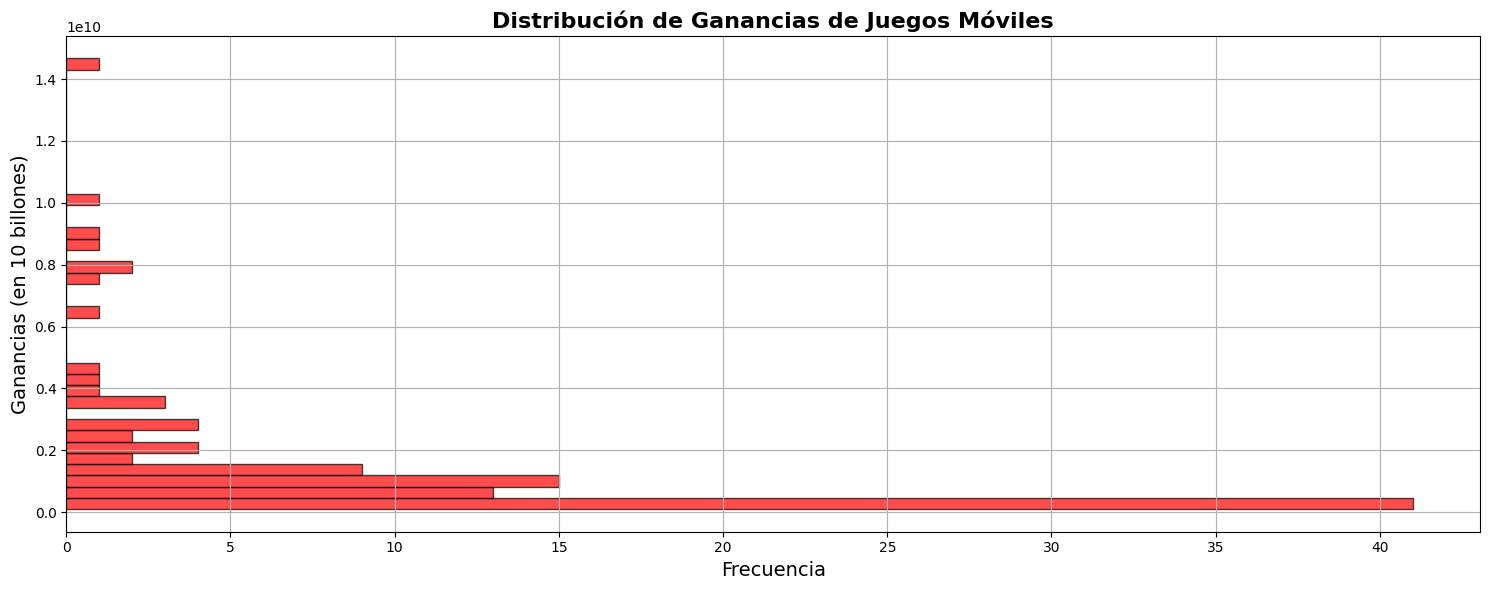

In [28]:
plt.figure(figsize=(15, 6)) 

mobile_games['Ganancias'].hist(bins=40, color='red', edgecolor='black', alpha=0.7, orientation='horizontal')

plt.title('Distribución de Ganancias de Juegos Móviles', fontsize=16, fontweight='bold')
plt.xlabel('Frecuencia', fontsize=14)  
plt.ylabel('Ganancias (en 10 billones)', fontsize=14) 

plt.tight_layout() 
plt.show()


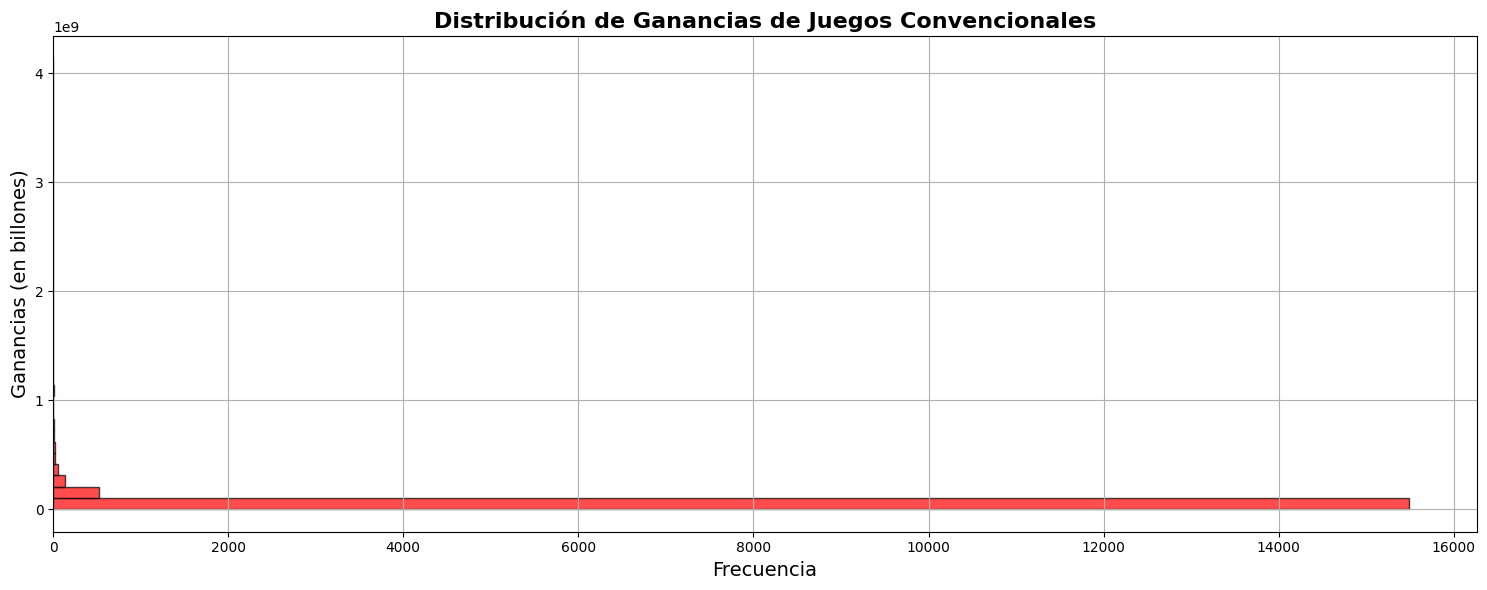

In [29]:
plt.figure(figsize=(15, 6))

convencional_games['Ganancias'].hist(bins=40, color='red', edgecolor='black', alpha=0.7, orientation='horizontal')

plt.title('Distribución de Ganancias de Juegos Convencionales', fontsize=16, fontweight='bold')
plt.xlabel('Frecuencia', fontsize=14)  
plt.ylabel('Ganancias (en billones)', fontsize=14) 

plt.tight_layout() 
plt.show()

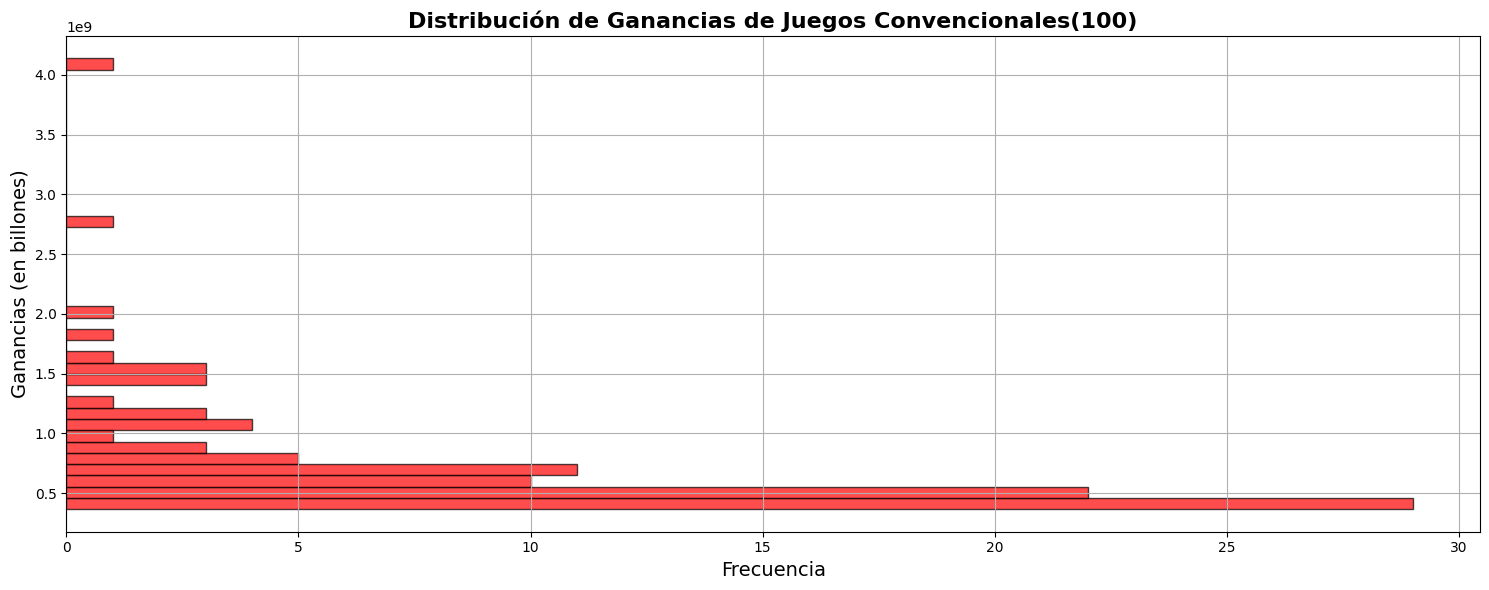

In [30]:
plt.figure(figsize=(15, 6)) 
convencional_games_100['Ganancias'].hist(bins=40, color='red', edgecolor='black', alpha=0.7, orientation='horizontal')

plt.title('Distribución de Ganancias de Juegos Convencionales(100)', fontsize=16, fontweight='bold')
plt.xlabel('Frecuencia', fontsize=14)  
plt.ylabel('Ganancias (en billones)', fontsize=14) 

plt.tight_layout() 
plt.show()

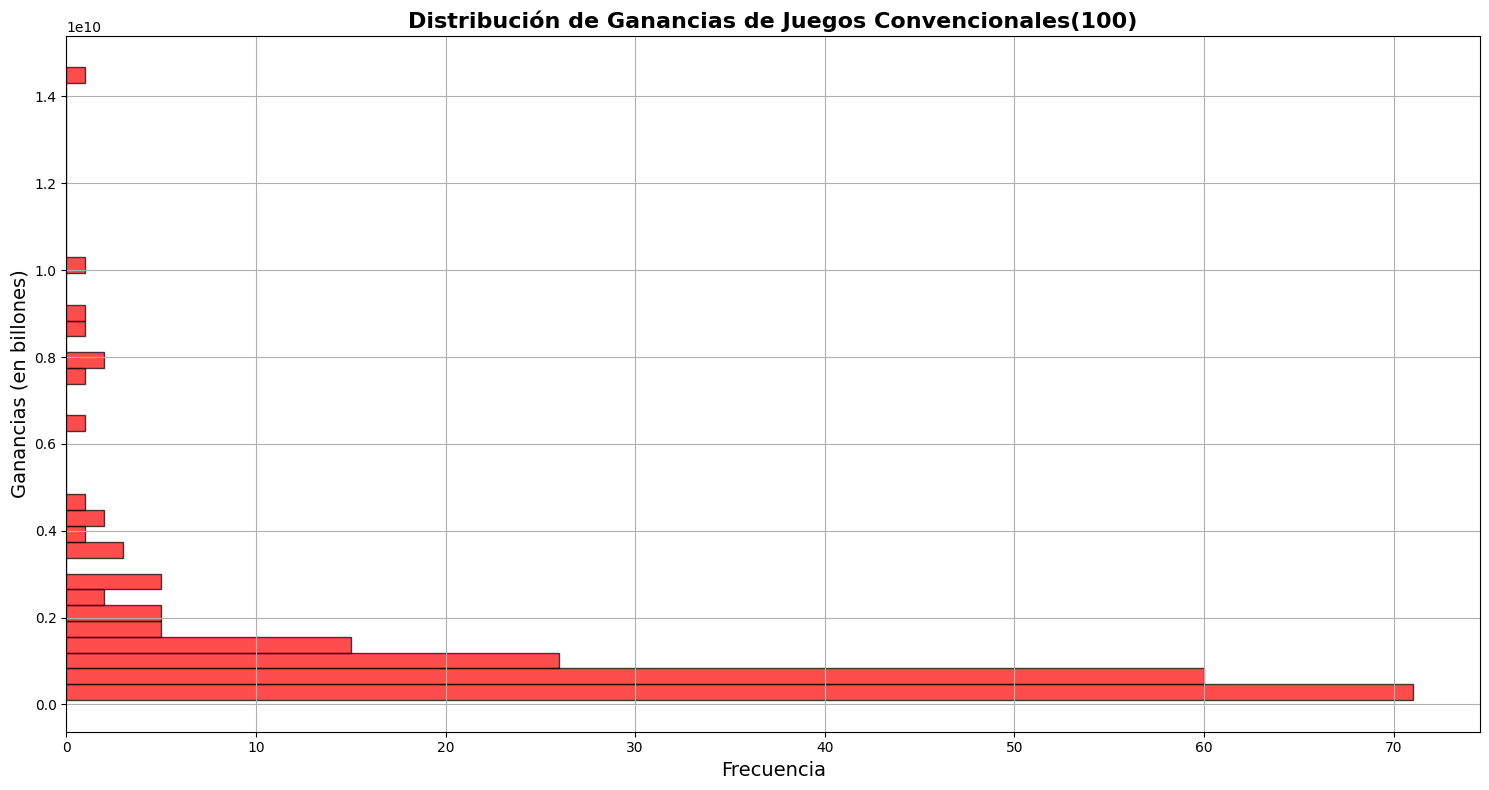

In [31]:
plt.figure(figsize=(15, 8)) 
videojuegos['Ganancias'].hist(bins=40, color='red', edgecolor='black', alpha=0.7, orientation='horizontal')

plt.title('Distribución de Ganancias de Juegos Convencionales(100)', fontsize=16, fontweight='bold')
plt.xlabel('Frecuencia', fontsize=14)  
plt.ylabel('Ganancias (en billones)', fontsize=14) 

plt.tight_layout() 
plt.show()

###  Visualizacion de juegos concretos y su respectiva ganancia de cada dataset creado anteriormente

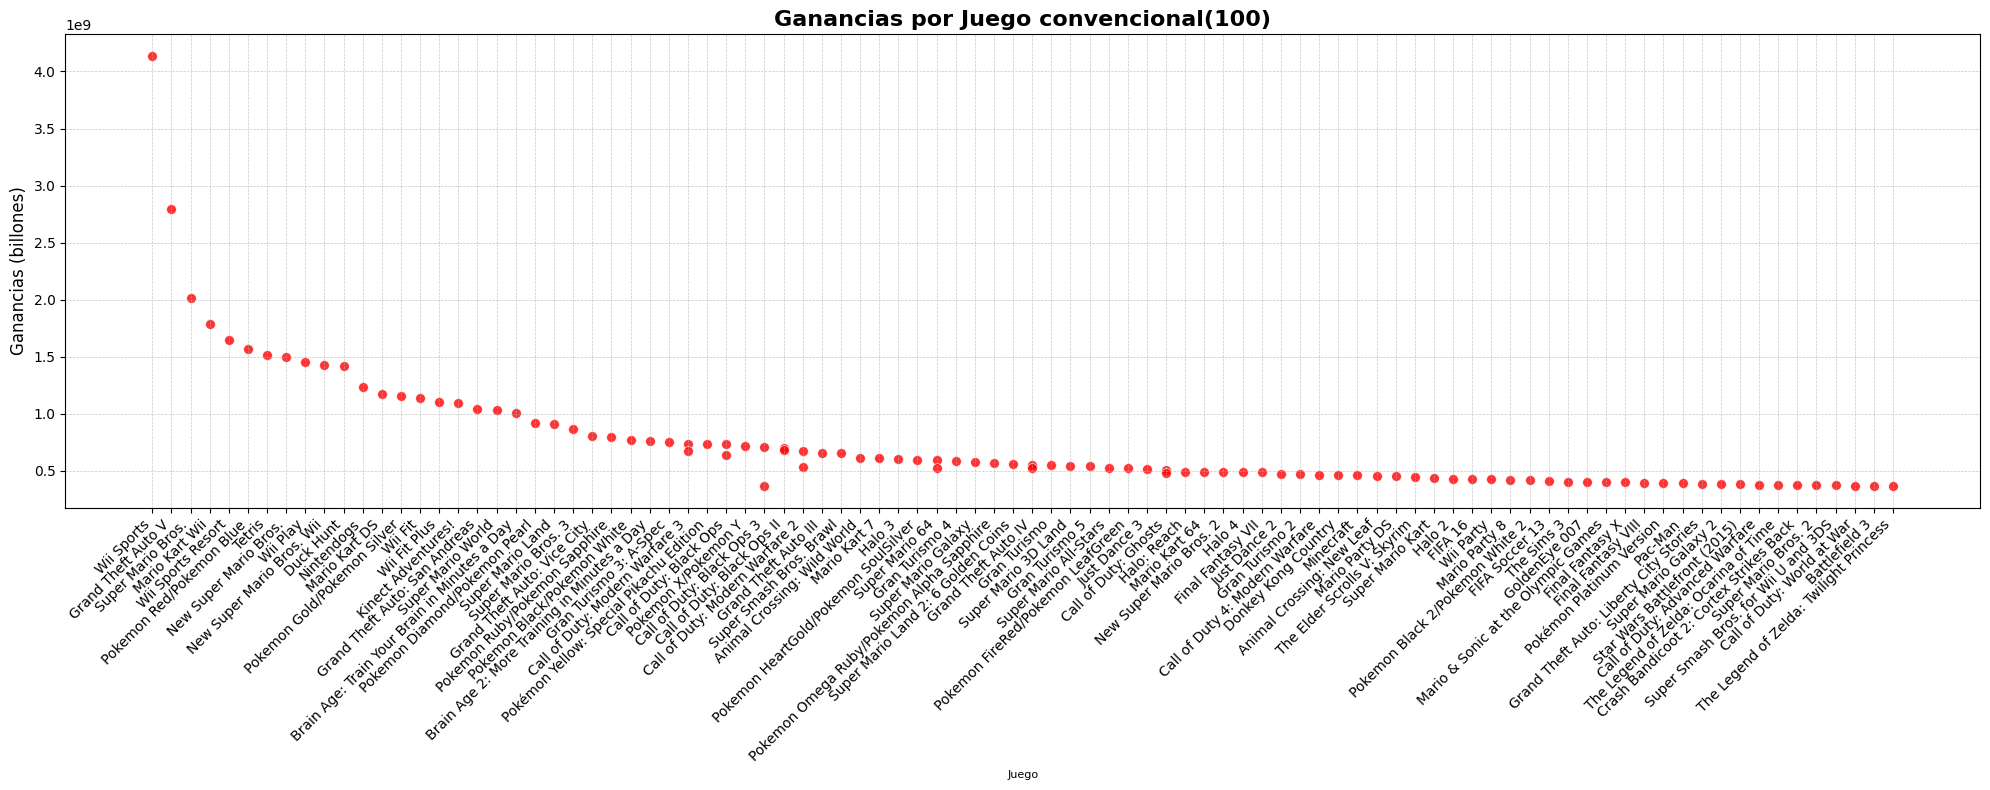

In [32]:
plt.figure(figsize=(20, 8))  # Ajustar el tamaño del gráfico
sns.scatterplot(x='Juego', y='Ganancias', data=convencional_games_100, s=50, color='red', alpha=0.8)
plt.title('Ganancias por Juego convencional(100)', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (billones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

C:\Users\Daygoro\AppData\Local\Temp\ipykernel_9820\2856915849.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Juego', y='Ganancias', data=convencional_games_100, palette='inferno', alpha=0.8)


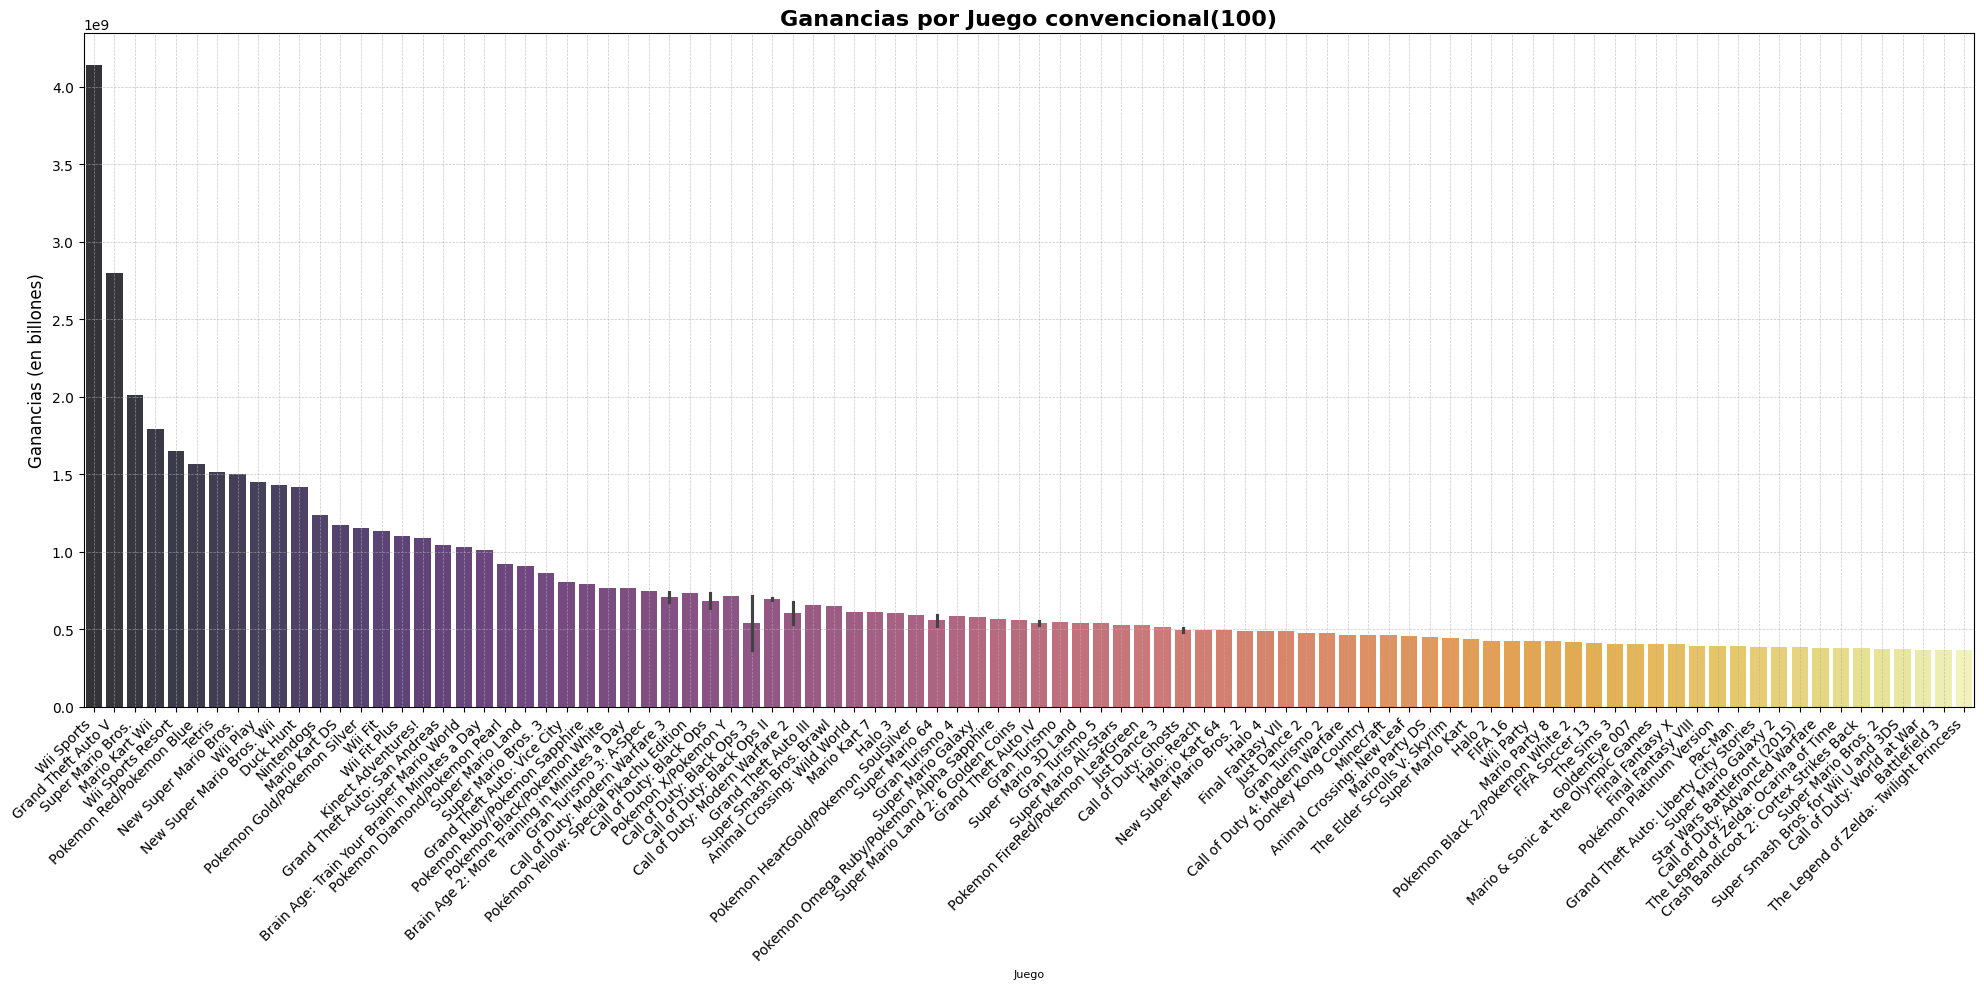

In [62]:
plt.figure(figsize=(20, 10))

sns.barplot(x='Juego', y='Ganancias', data=convencional_games_100, palette='inferno', alpha=0.8)

plt.title('Ganancias por Juego convencional(100)', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (en billones)', fontsize=12)

plt.xticks(rotation=45, ha='right', fontsize=10)

plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()

plt.show()

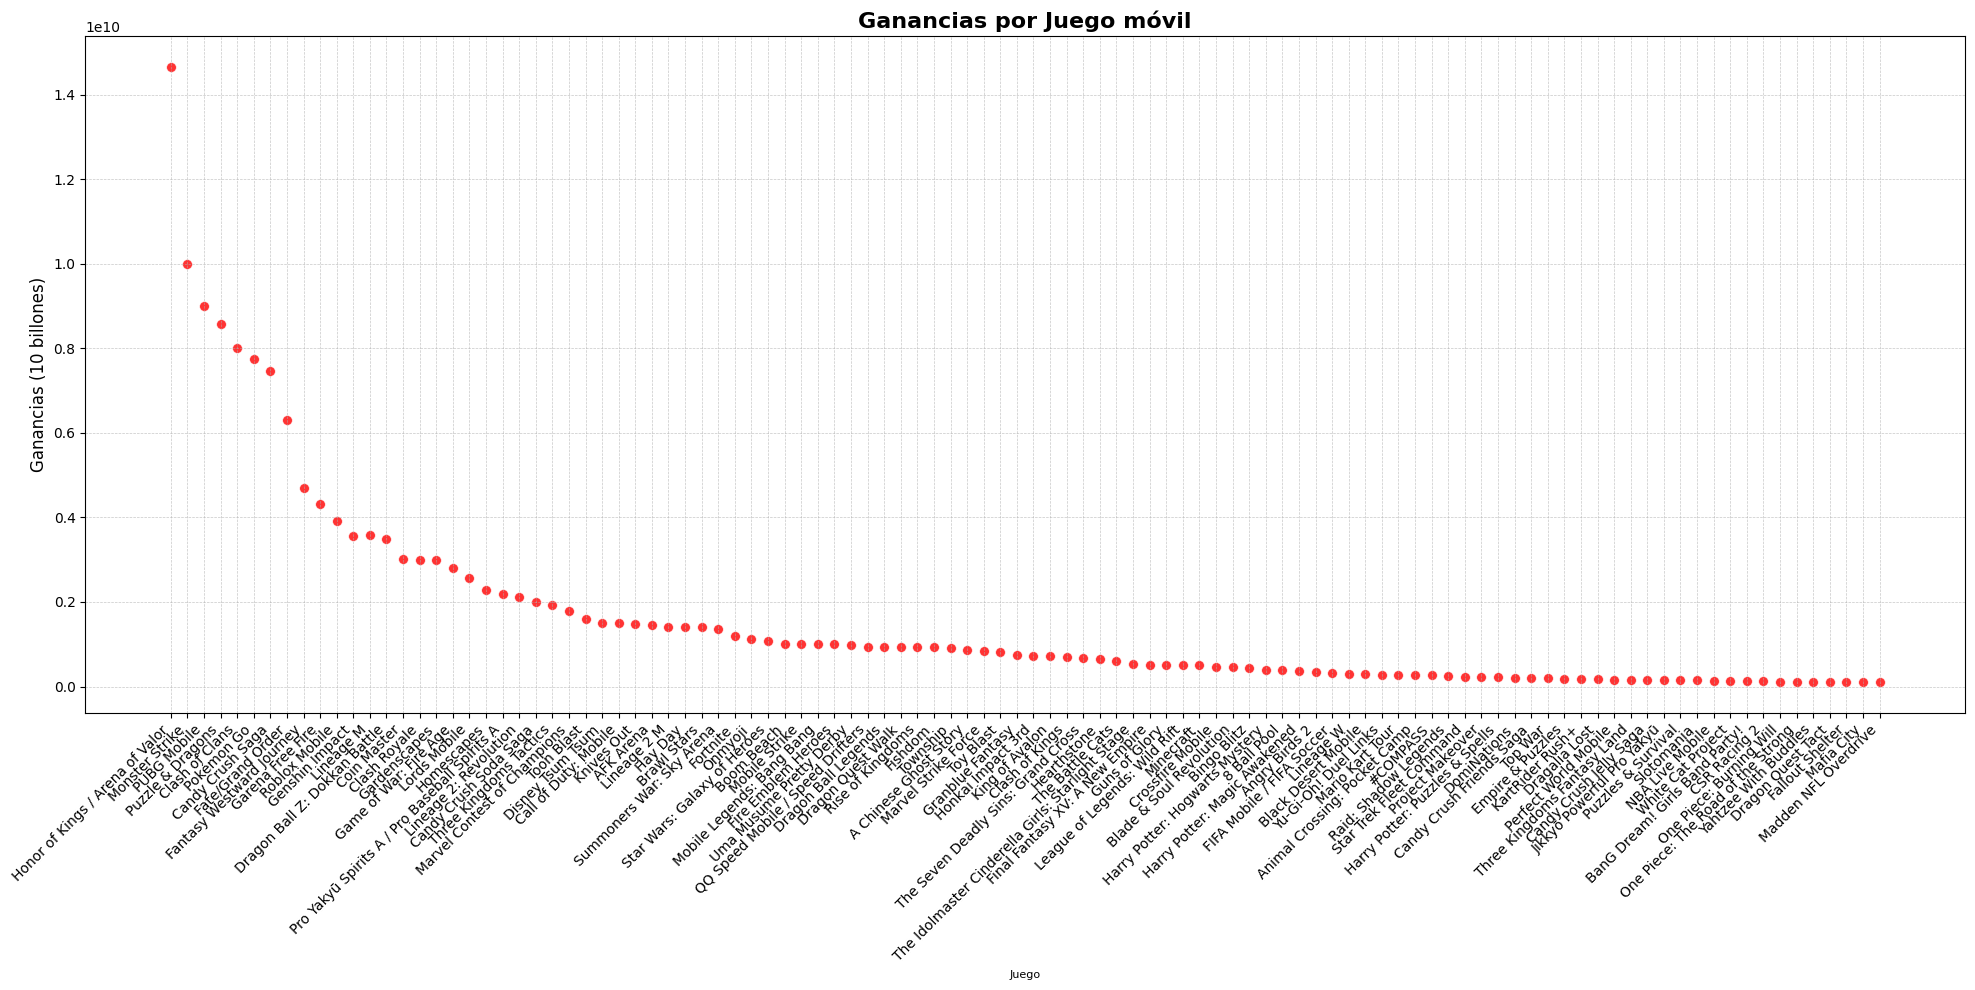

In [33]:
plt.figure(figsize=(20, 10))
sns.scatterplot(x='Juego', y='Ganancias', data=mobile_games, s=50, color='red', alpha=0.8)
plt.title('Ganancias por Juego móvil', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (10 billones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()



C:\Users\Daygoro\AppData\Local\Temp\ipykernel_9820\3877923013.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Juego', y='Ganancias', data=mobile_games, palette='inferno', alpha=0.8)


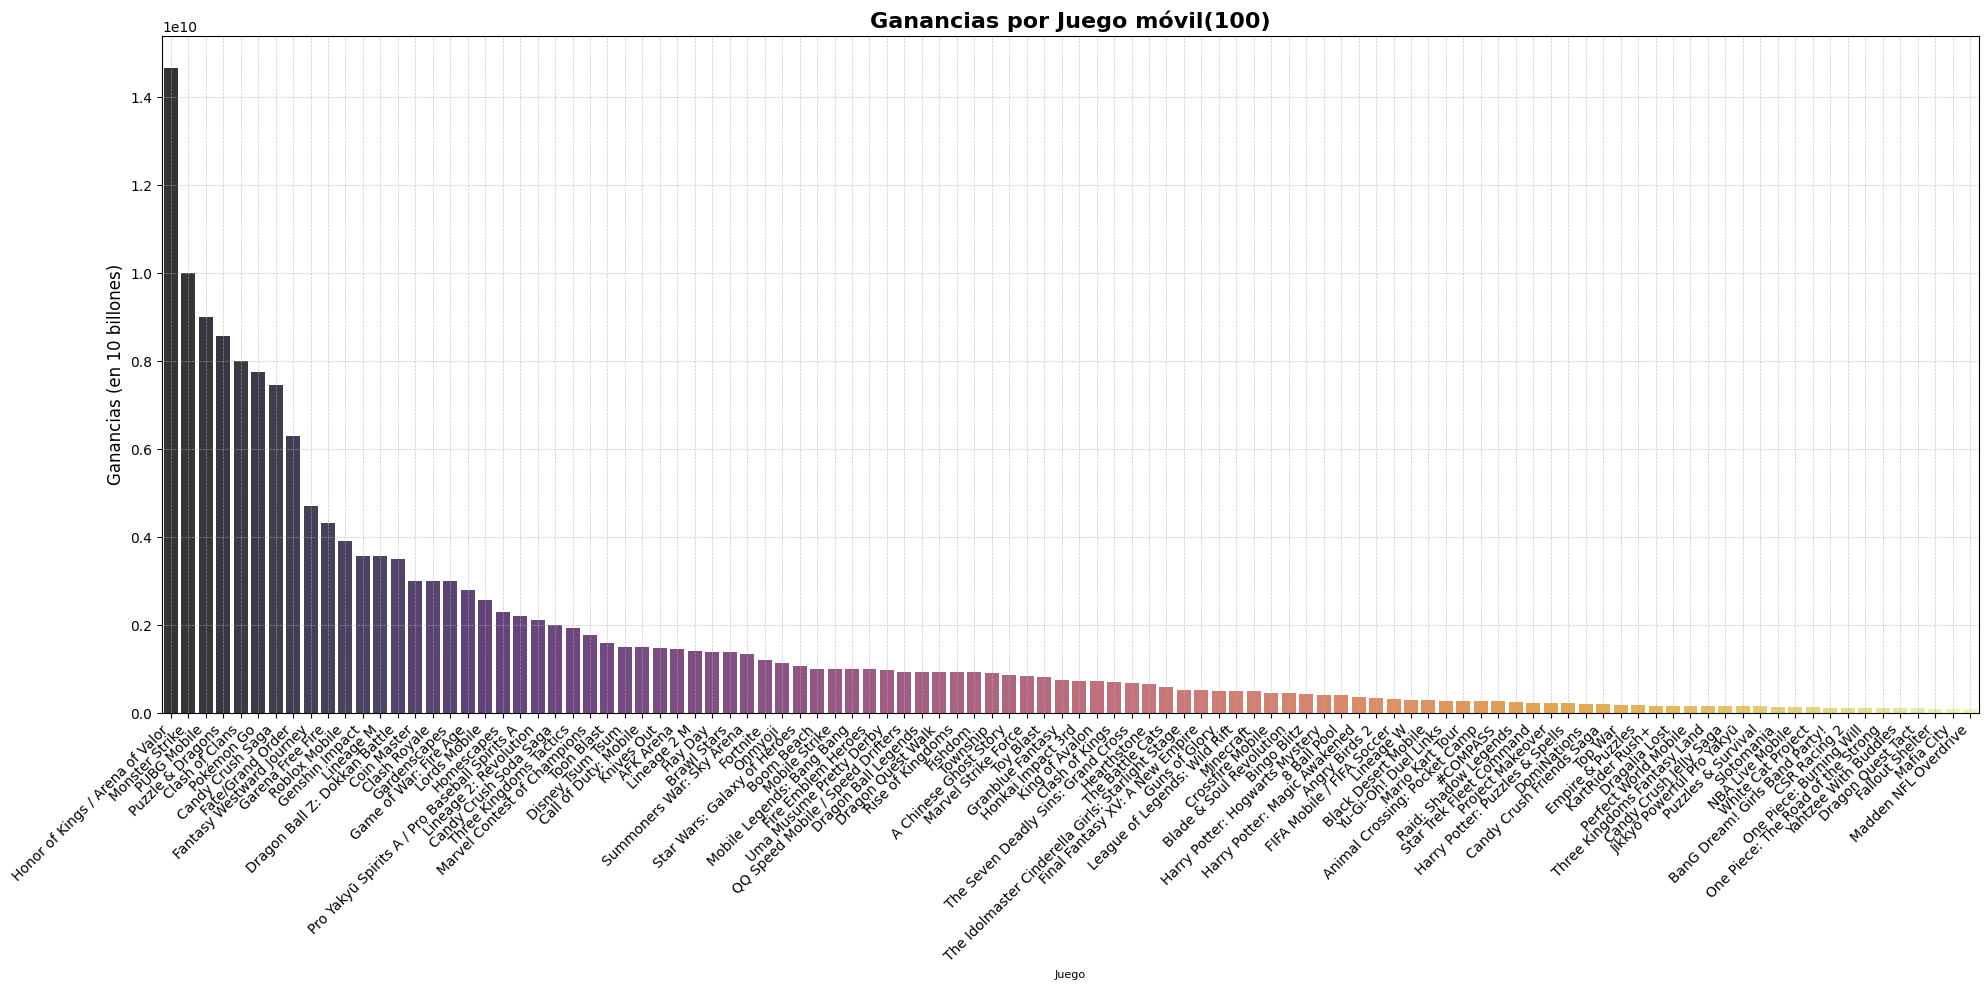

In [63]:
plt.figure(figsize=(20, 10))

sns.barplot(x='Juego', y='Ganancias', data=mobile_games, palette='inferno', alpha=0.8)

plt.title('Ganancias por Juego móvil(100)', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (en 10 billones)', fontsize=12)

plt.xticks(rotation=45, ha='right', fontsize=10)

plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()

plt.show()

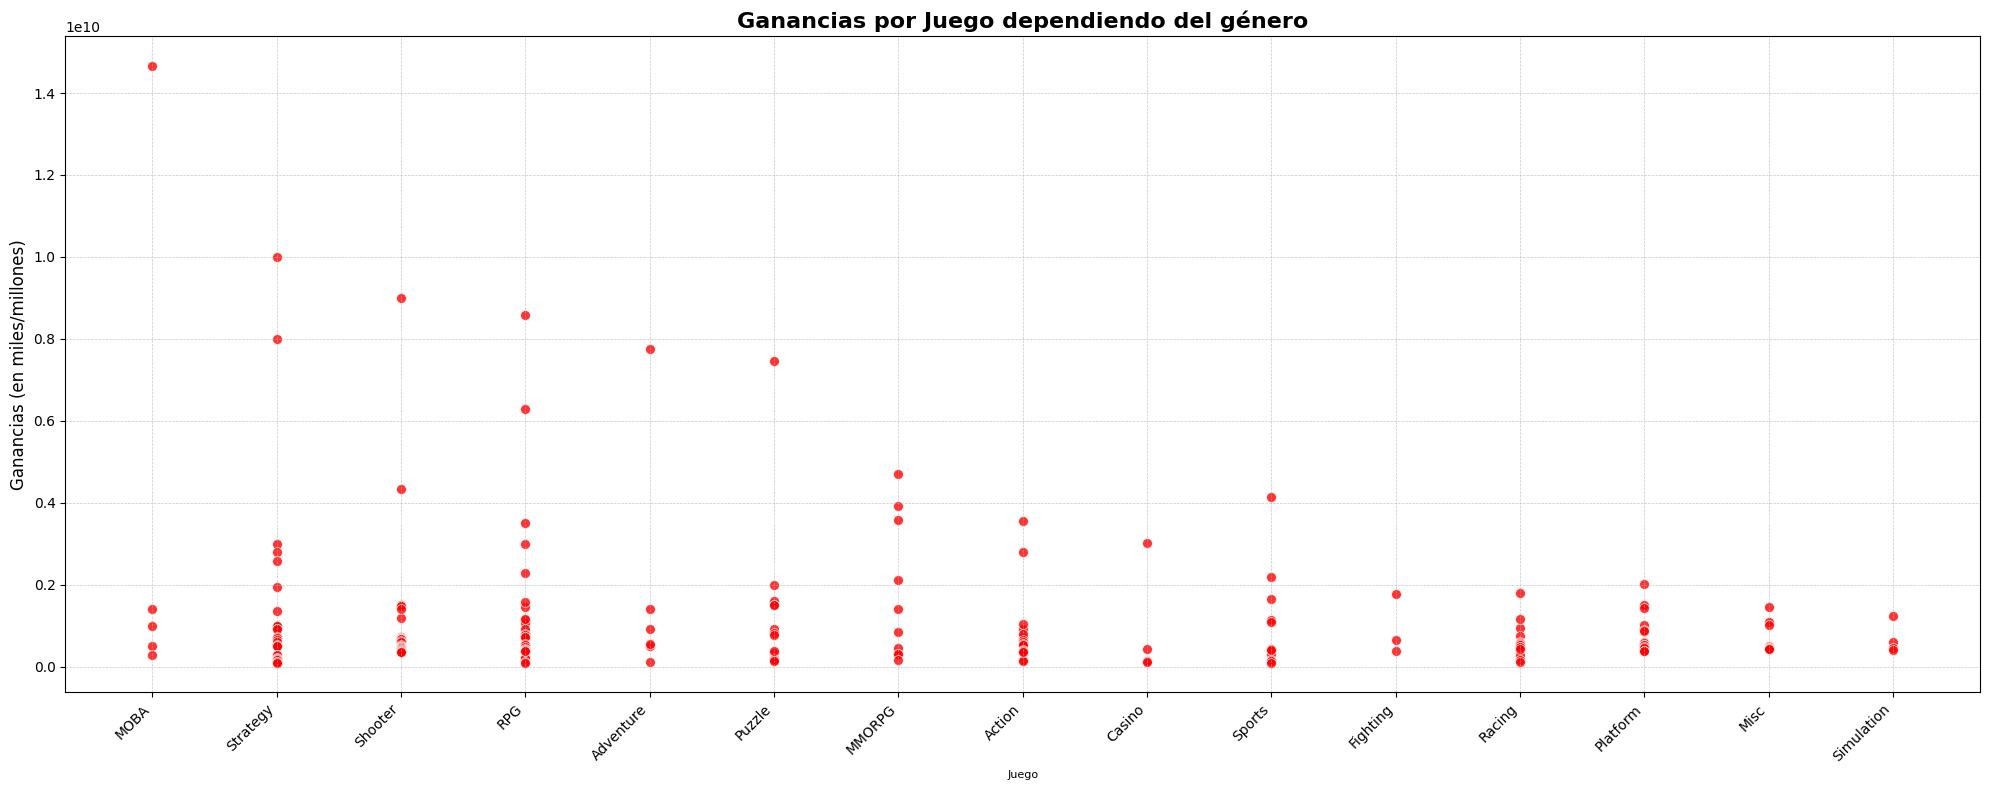

In [34]:
plt.figure(figsize=(20, 8))  # Ajustar el tamaño del gráfico
sns.scatterplot(x='Genero', y='Ganancias', data=videojuegos, s=50, color='red', alpha=0.8)
plt.title('Ganancias por Juego dependiendo del género', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (en miles/millones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

##### Ordenamos por fecha los datasets creados para poder verlos de forma cronológica

In [60]:
mobile_games_fecha = mobile_games.sort_values(by='Fecha', ascending=True)
mobile_games_fecha

,Juego,Ganancias,Fecha,Empresa,Genero
67,8 Ball Pool,400000000,2010,Miniclip,Sports
62,Minecraft,500000000,2011,Mojang Studios,Adventure
92,Slotomania,149000000,2011,Playtika,Casino
3,Puzzle & Dragons,8578340000,2012,GungHo Online Entertainment,RPG
31,Hay Day,1400000000,2012,Supercell (Tencent),Adventure
...,...,...,...,...,...
91,Puzzles & Survival,151000000,2020,37Games,Puzzle
100,Dragon Quest Tact,111990000,2020,Square Enix,Strategy
41,Uma Musume Pretty Derby,990000000,2021,Cygames,Strategy
71,Lineage W,302985000,2021,NCsoft,MMORPG


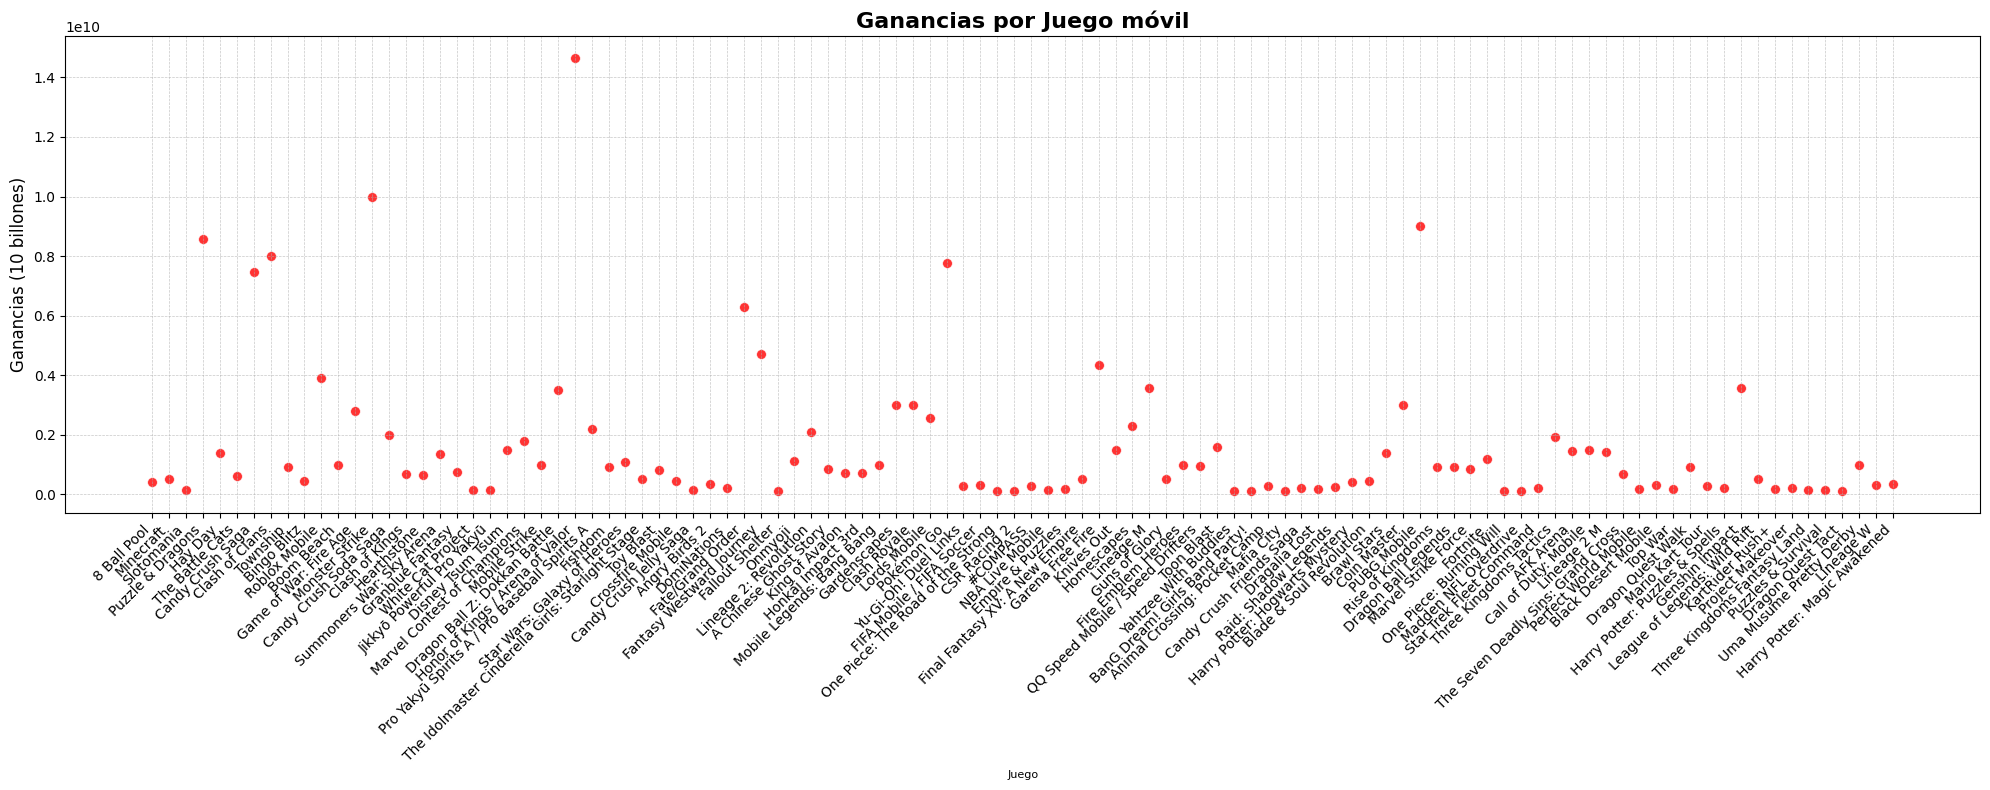

In [36]:
plt.figure(figsize=(20, 8))  # Ajustar el tamaño del gráfico
sns.scatterplot(x='Juego', y='Ganancias', data=mobile_games_fecha, s=50, color='red', alpha=0.8)
plt.title('Ganancias por Juego móvil', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (10 billones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

In [61]:
convencional_games_100_fecha = convencional_games_100.sort_values(by='Fecha', ascending=True)
convencional_games_100_fecha

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
86,Pac-Man,390500000,1982,Atari,Puzzle,2600,7280000,450000,0,80000,7810000
9,Duck Hunt,1415500000,1984,Nintendo,Shooter,NES,26930000,630000,280000,470000,28310000
1,Super Mario Bros.,2012000000,1985,Nintendo,Platform,NES,29080000,3580000,6810000,770000,40240000
21,Super Mario Bros. 3,864000000,1988,Nintendo,Platform,NES,9540000,3440000,3840000,460000,17280000
93,Super Mario Bros. 2,373000000,1988,Nintendo,Platform,NES,5390000,1180000,700000,190000,7460000
...,...,...,...,...,...,...,...,...,...,...,...
94,Super Smash Bros. for Wii U and 3DS,372500000,2014,Nintendo,Fighting,3DS,3240000,1350000,2420000,430000,7450000
31,Call of Duty: Black Ops 3,712000000,2015,Activision,Shooter,PS4,5770000,5810000,350000,2310000,14240000
74,FIFA 16,424500000,2015,Electronic Arts,Sports,PS4,1110000,6060000,60000,1260000,8490000
89,Star Wars Battlefront (2015),383500000,2015,Electronic Arts,Shooter,PS4,2930000,3290000,220000,1230000,7670000


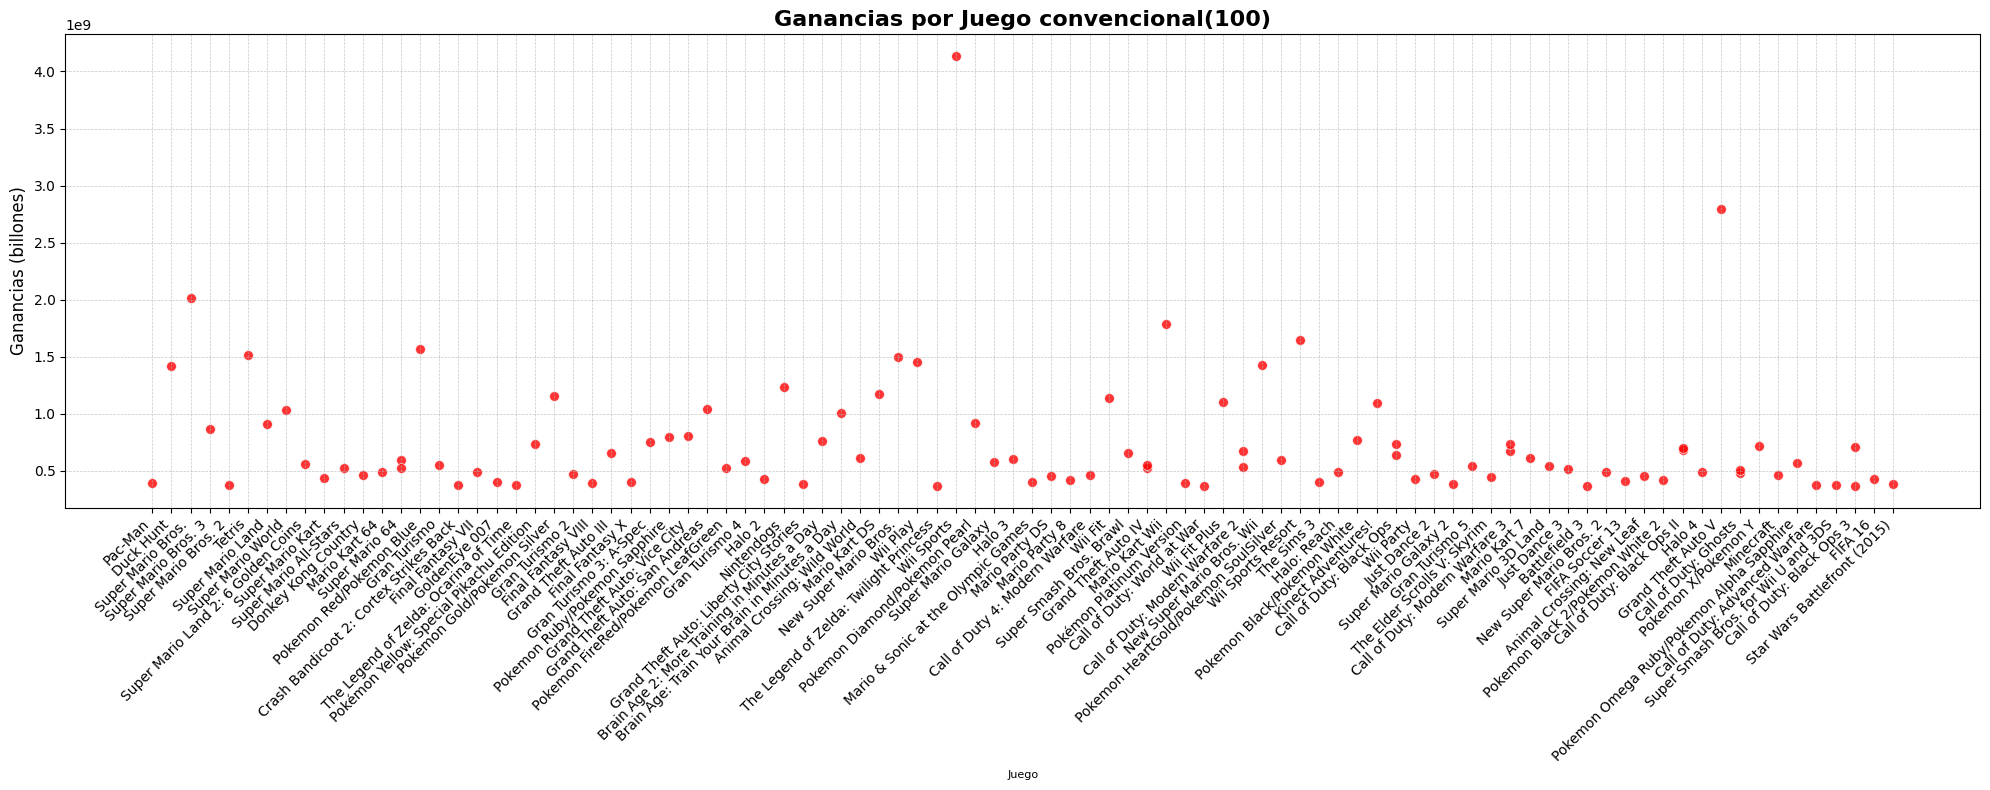

In [41]:
plt.figure(figsize=(20, 8))  # Ajustar el tamaño del gráfico
sns.scatterplot(x='Juego', y='Ganancias', data=convencional_games_100_fecha, s=50, color='red', alpha=0.8)
plt.title('Ganancias por Juego convencional(100)', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (billones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

#### Al filtrar los 100 mejores datasets, los juegos convencionales actuales (hasta el 2020 que es lo maximo que llegue el dataset) no aparecen

Por lo tanto creamos otra variable con los ultimo 100 juegos mas recientes para ver lo bajo que estan

In [42]:
convencional_games_100_fecha_new = convencional_games.sort_values(by='Fecha', ascending=False)
convencional_games_100_fecha_new = convencional_games_100_fecha_new.iloc[:100]
convencional_games_100_fecha_new

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
5855,Imagine: Makeup Artist,14500000,2020,Ubisoft,Simulation,DS,270000,0,0,20000,290000
14131,Phantasy Star Online 2 Episode 4: Deluxe Package,1500000,2017,Sega,RPG,PS4,0,0,30000,0,30000
15939,Phantasy Star Online 2 Episode 4: Deluxe Package,500000,2017,Sega,RPG,PSV,0,0,10000,0,10000
16130,Brothers Conflict: Precious Baby,500000,2017,Idea Factory,Action,PSV,0,0,10000,0,10000
12402,Super Robot Wars OG: The Moon Dwellers,3000000,2016,Namco Bandai Games,Misc,PS3,0,0,60000,0,60000
...,...,...,...,...,...,...,...,...,...,...,...
14378,Ao no Kanata no Four Rhythm,1500000,2016,Unknown,Adventure,PSV,0,0,30000,0,30000
14417,Ghostbusters (2016),1500000,2016,Activision,Action,PS4,20000,0,0,10000,30000
8497,Yakuza Kiwami,8000000,2016,Sega,Adventure,PS4,0,0,160000,0,160000
13638,Hatsune Miku: Project Diva X,2000000,2016,Sega,Misc,PS4,10000,0,20000,0,40000


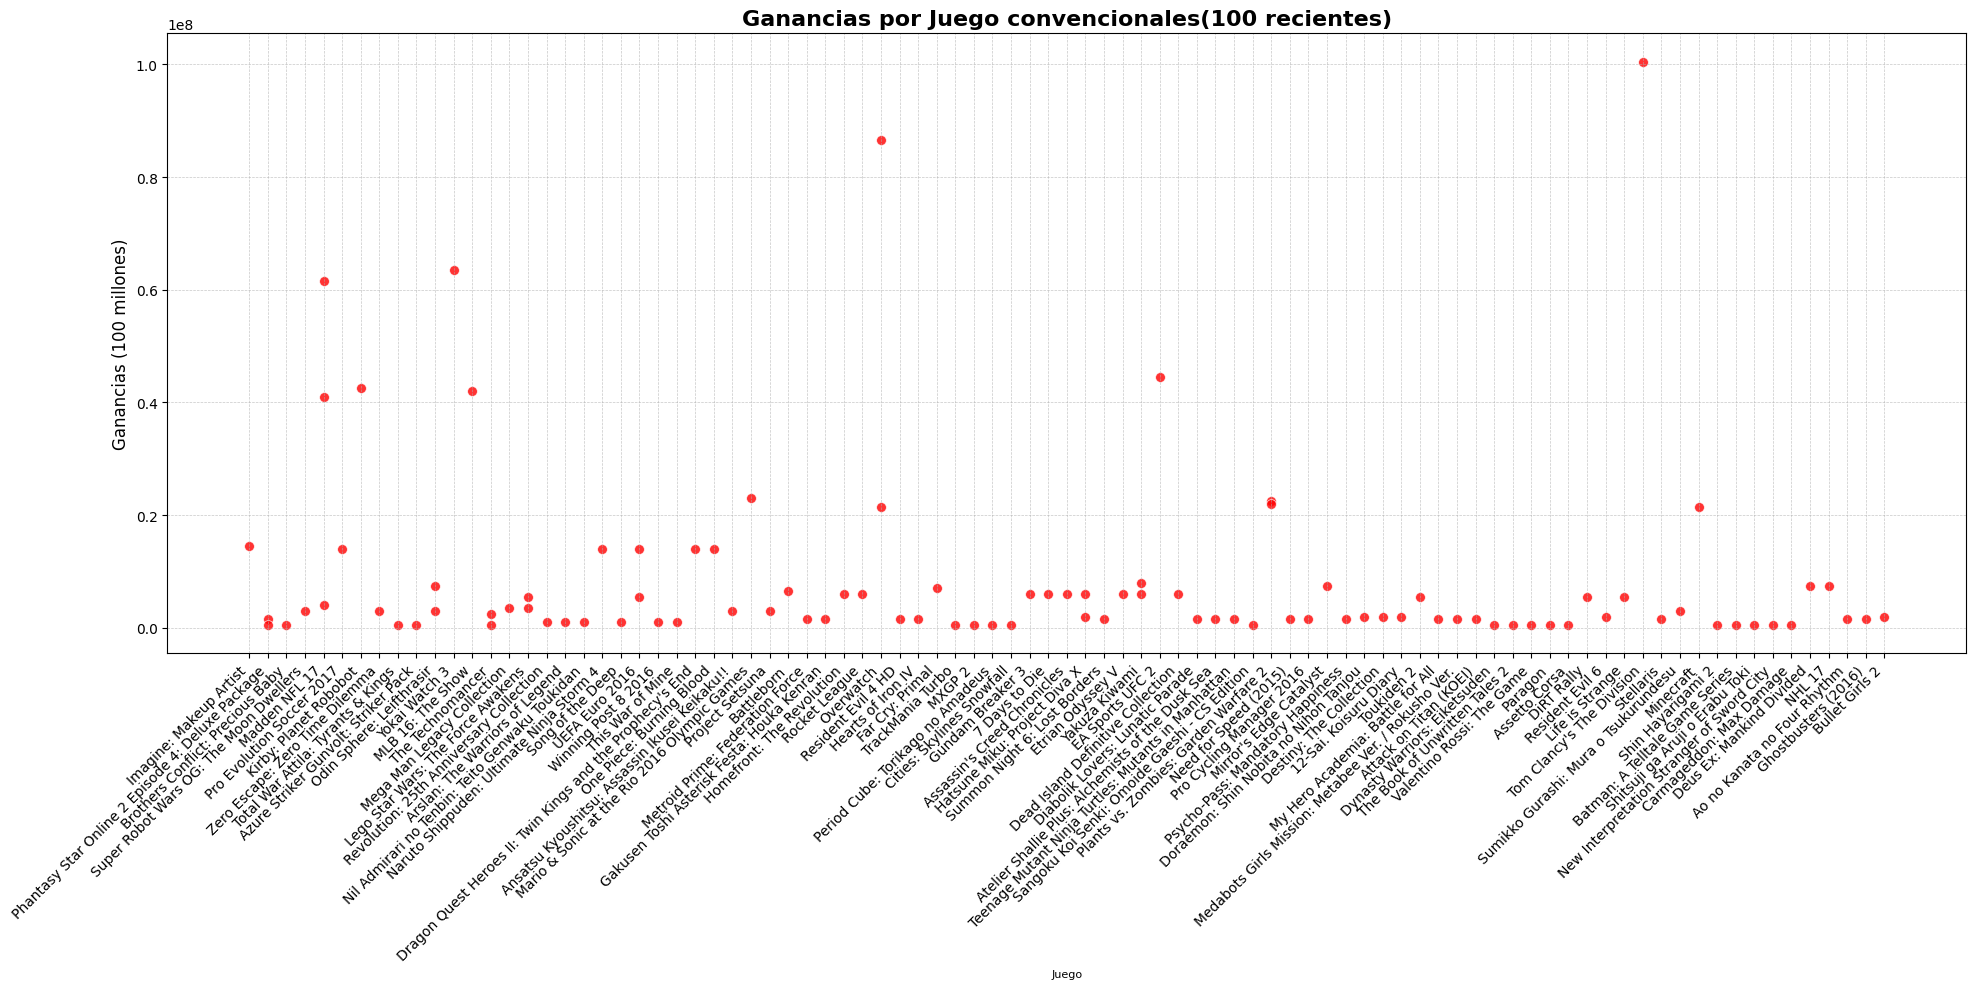

In [43]:
plt.figure(figsize=(20, 10))  # Ajustar el tamaño del gráfico
sns.scatterplot(x='Juego', y='Ganancias', data=convencional_games_100_fecha_new, s=50, color='red', alpha=0.8)
plt.title('Ganancias por Juego convencionales(100 recientes)', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (100 millones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

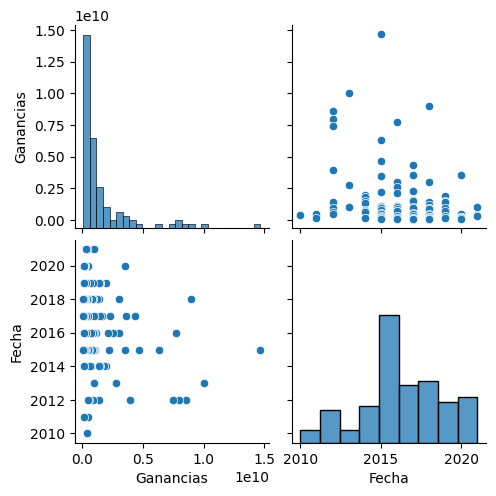

In [70]:
sns.pairplot(mobile_games)


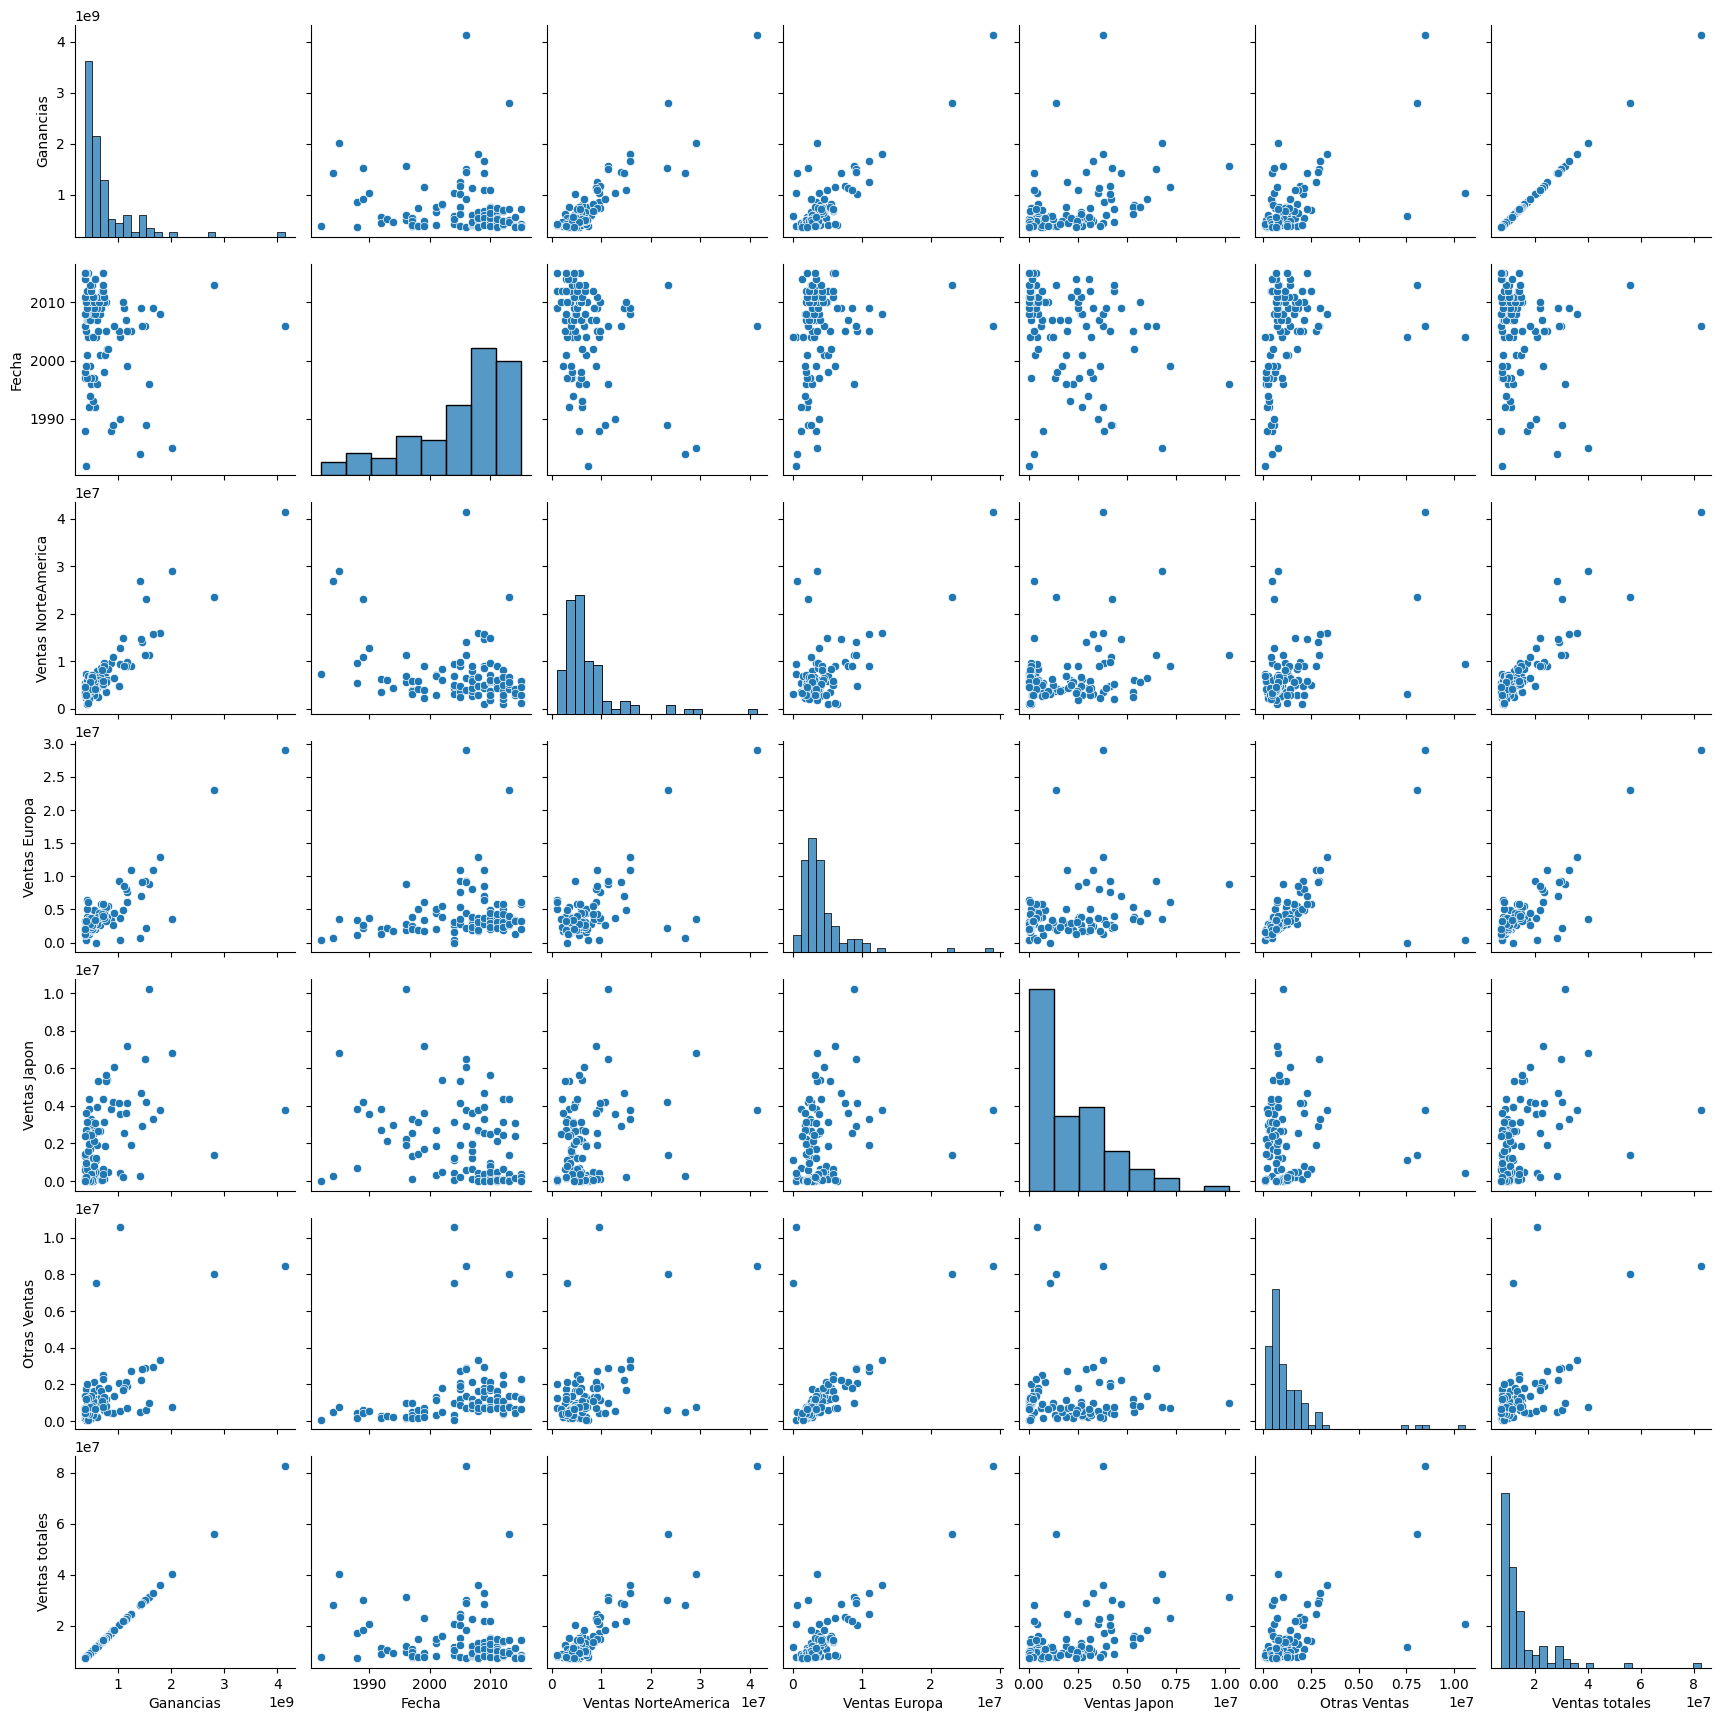

In [71]:
sns.pairplot(convencional_games_100_fecha)


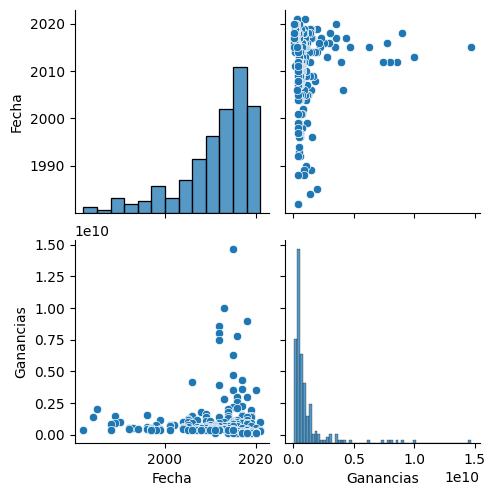

In [72]:
sns.pairplot(videojuegos)


C:\Users\Daygoro\AppData\Local\Temp\ipykernel_9820\221126510.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Juego', y='Ganancias', data=convencional_games_100_fecha_new, palette='inferno', alpha=0.8)


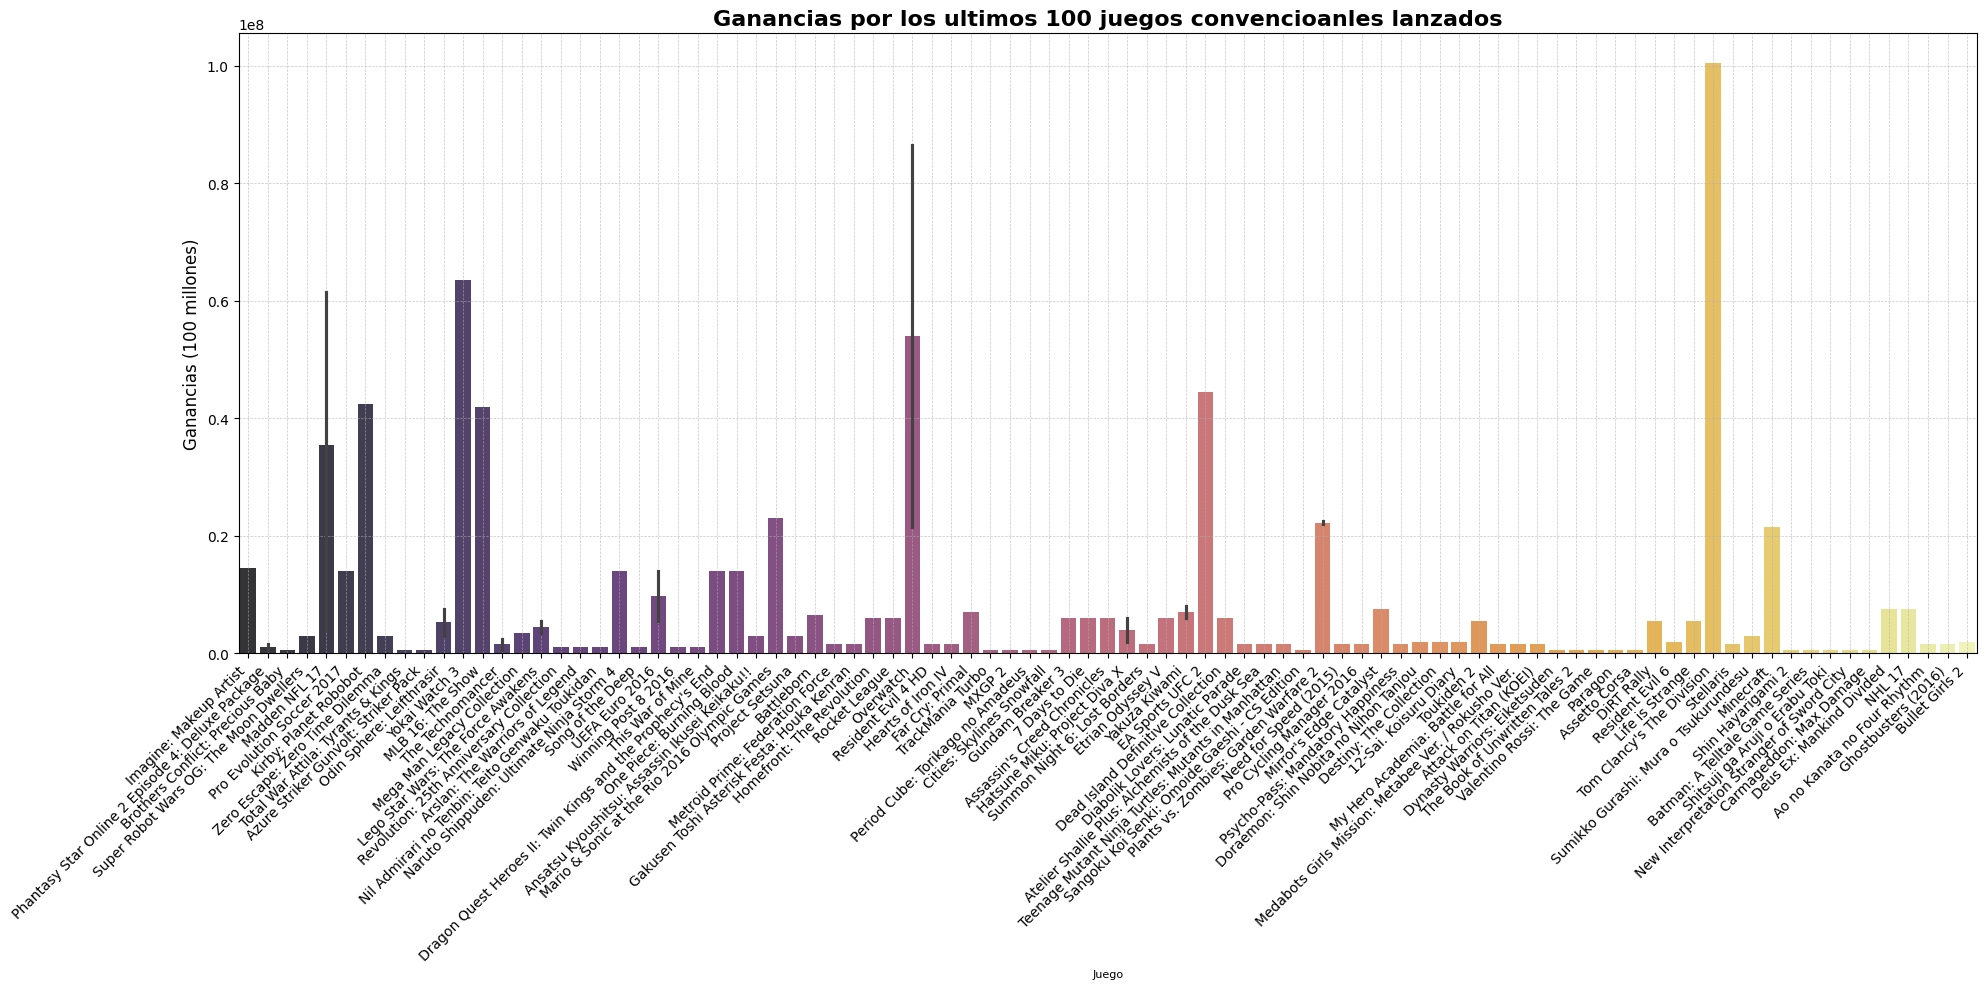

In [44]:
plt.figure(figsize=(20, 10))
sns.barplot(x='Juego', y='Ganancias', data=convencional_games_100_fecha_new, palette='inferno', alpha=0.8)
plt.title('Ganancias por los ultimos 100 juegos convencioanles lanzados', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (100 millones)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()

plt.show()

#### Sacamos gráficas ordenadas cronológicamente

C:\Users\Daygoro\AppData\Local\Temp\ipykernel_9820\3565636337.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Juego', y='Ganancias', data=mobile_games_fecha, palette='inferno', alpha=0.8)


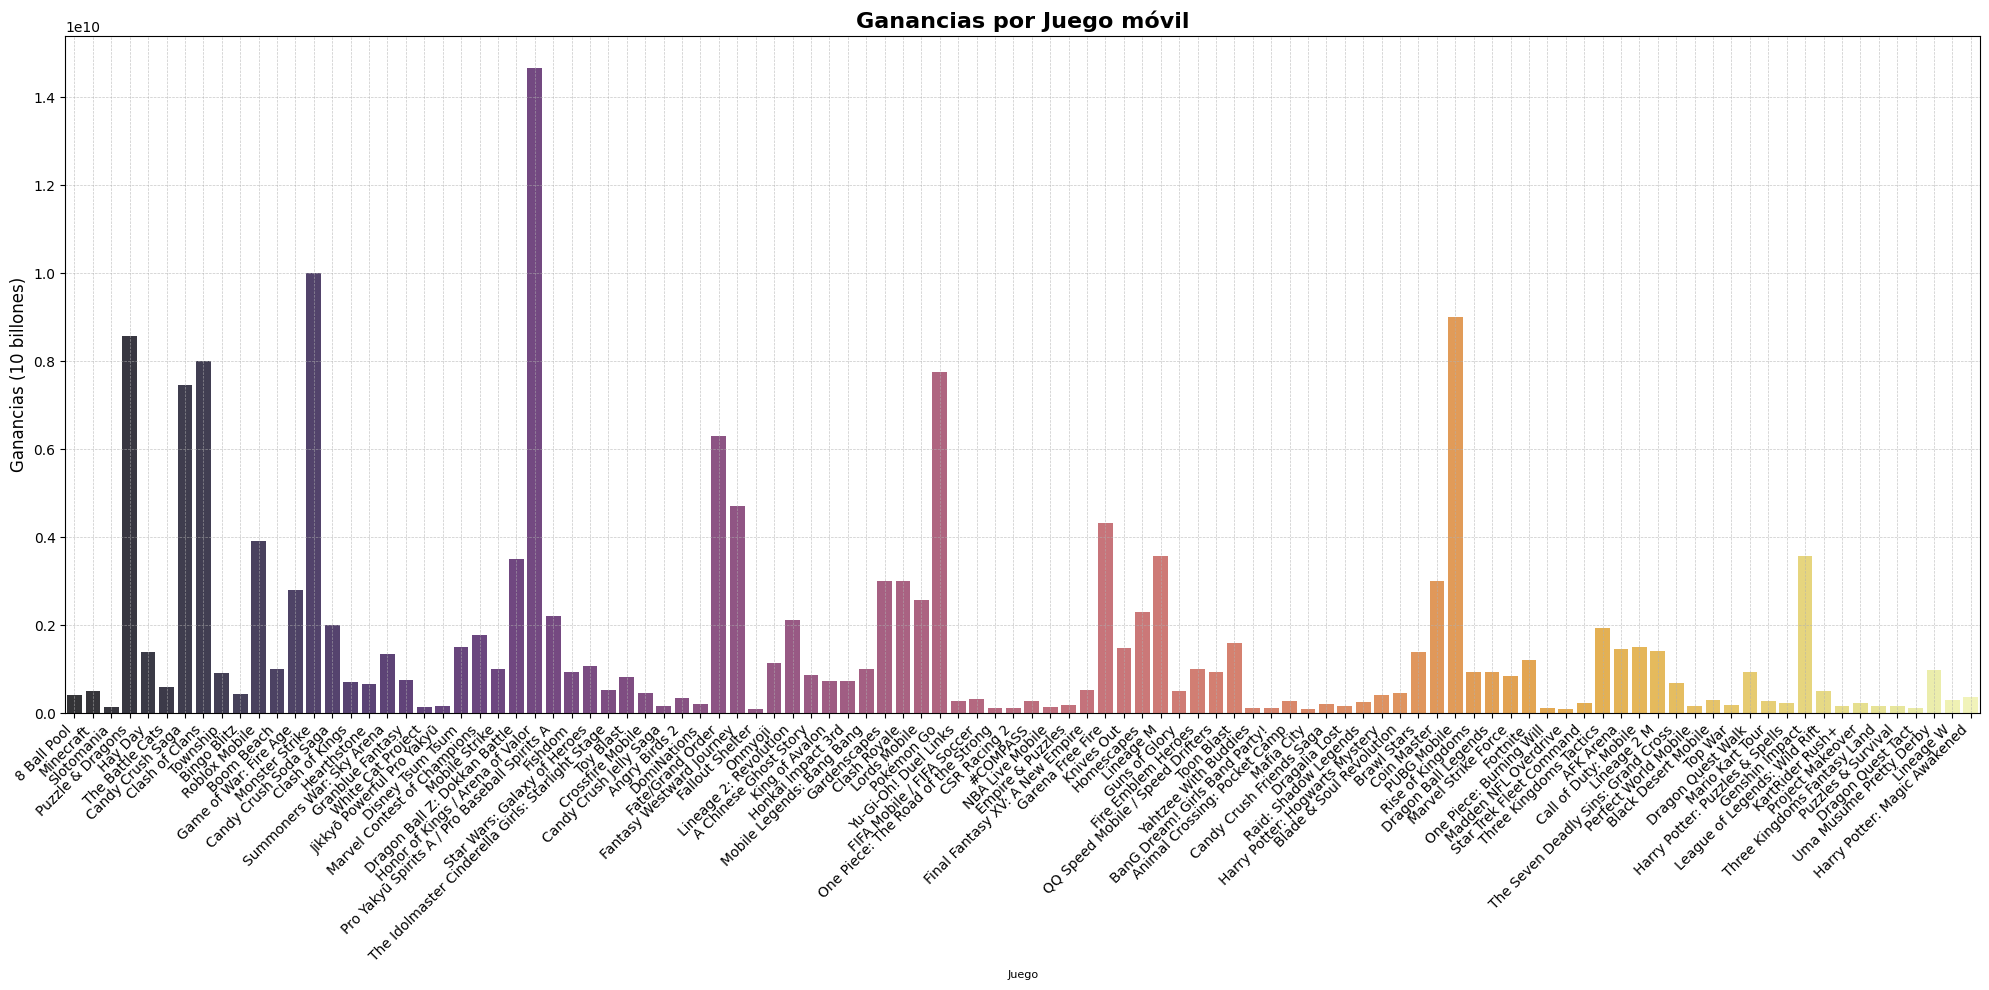

In [59]:
plt.figure(figsize=(20, 10))

sns.barplot(x='Juego', y='Ganancias', data=mobile_games_fecha, palette='inferno', alpha=0.8)

plt.title('Ganancias por Juego móvil', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (10 billones)', fontsize=12)

plt.xticks(rotation=45, ha='right', fontsize=10)

plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()

plt.show()

C:\Users\Daygoro\AppData\Local\Temp\ipykernel_9820\1327079744.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Juego', y='Ganancias', data=convencional_games_100_fecha, palette='inferno', alpha=0.8)


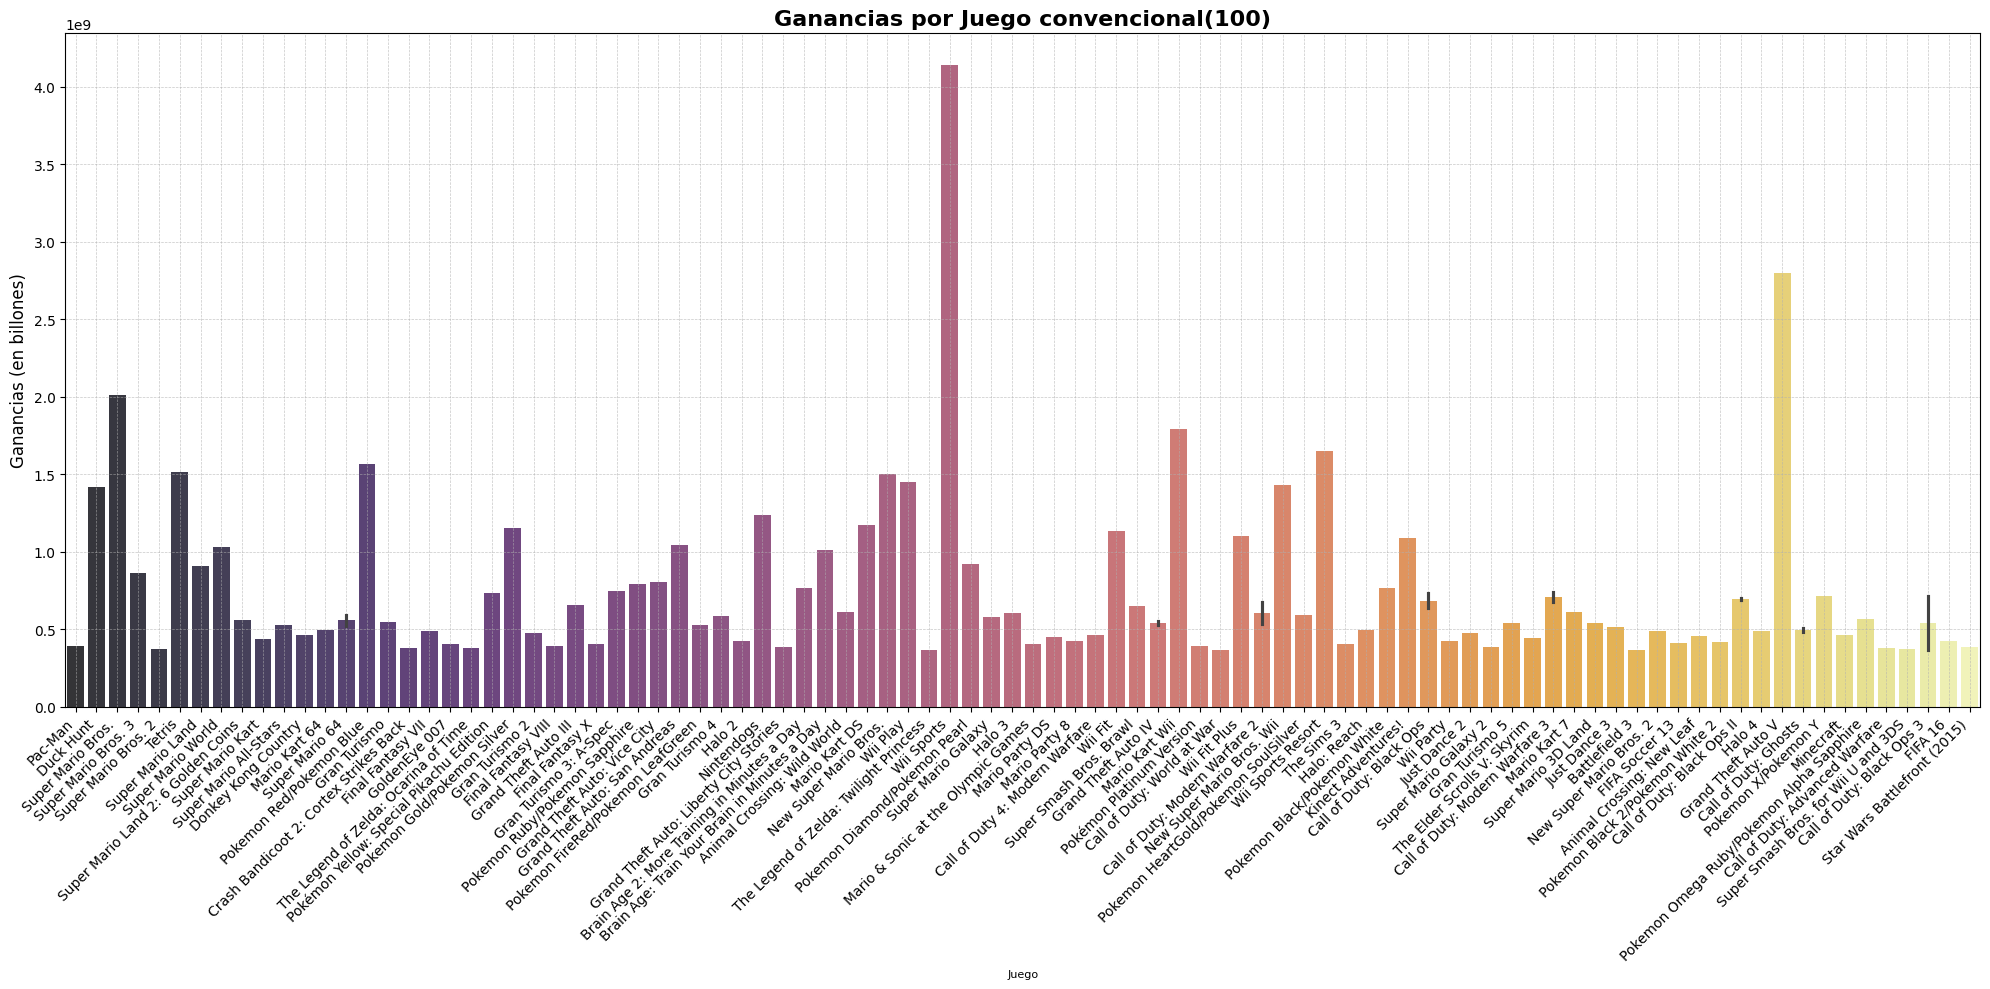

In [50]:
plt.figure(figsize=(20, 10))

sns.barplot(x='Juego', y='Ganancias', data=convencional_games_100_fecha, palette='inferno', alpha=0.8)

plt.title('Ganancias por Juego convencional(100)', fontsize=16, fontweight='bold')
plt.xlabel('Juego', fontsize=8)
plt.ylabel('Ganancias (en billones)', fontsize=12)

plt.xticks(rotation=45, ha='right', fontsize=10)

plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()

plt.show()

### Comparacion de los dos datasets

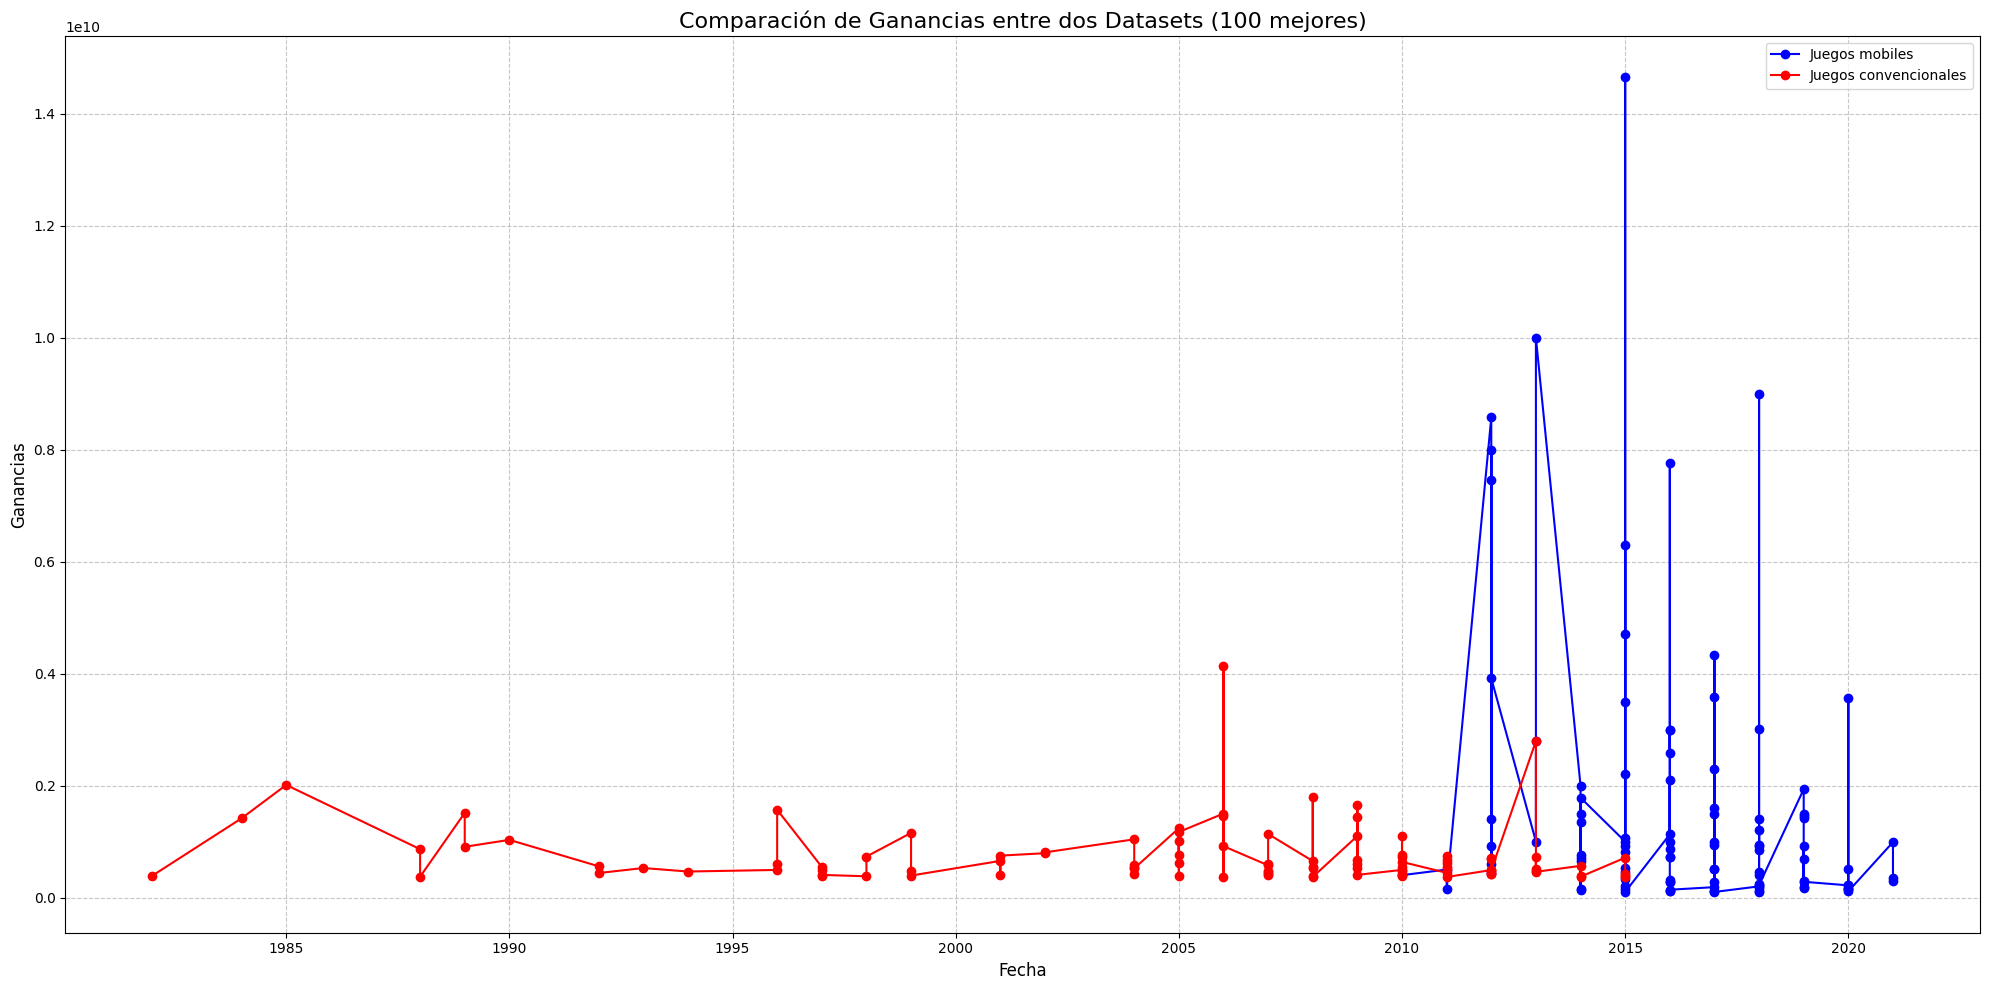

In [84]:
plt.figure(figsize=(20, 10))

plt.plot(mobile_games_fecha['Fecha'], mobile_games_fecha['Ganancias'], label='Juegos mobiles', color='blue', marker='o')

plt.plot(convencional_games_100_fecha['Fecha'], convencional_games_100_fecha['Ganancias'], label='Juegos convencionales', color='red', marker='o')

plt.title('Comparación de Ganancias entre dos Datasets (100 mejores)', fontsize=16)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Ganancias', fontsize=12)

plt.legend()
plt.grid(visible=True, which='major', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

In [85]:
convencional_games_fecha = convencional_games.sort_values(by='Fecha', ascending=True)
convencional_games_fecha

,Juego,Ganancias,Fecha,Empresa,Genero,Plataforma,Ventas NorteAmerica,Ventas Europa,Ventas Japon,Otras Ventas,Ventas totales
5307,Freeway,17000000,1980,Activision,Action,2600,320000,20000,0,0,340000
6243,Bridge,13500000,1980,Activision,Misc,2600,250000,20000,0,0,270000
3967,Ice Hockey,24500000,1980,Activision,Sports,2600,460000,30000,0,10000,490000
536,Missile Command,138000000,1980,Atari,Shooter,2600,2560000,170000,0,30000,2760000
253,Asteroids,215500000,1980,Atari,Shooter,2600,4000000,260000,0,50000,4310000
...,...,...,...,...,...,...,...,...,...,...,...
12177,Valentino Rossi: The Game,3000000,2016,Namco Bandai Games,Racing,PS4,10000,50000,0,10000,60000
16201,Brothers Conflict: Precious Baby,500000,2017,Idea Factory,Action,PSV,0,0,10000,0,10000
16008,Phantasy Star Online 2 Episode 4: Deluxe Package,500000,2017,Sega,RPG,PSV,0,0,10000,0,10000
14168,Phantasy Star Online 2 Episode 4: Deluxe Package,1500000,2017,Sega,RPG,PS4,0,0,30000,0,30000


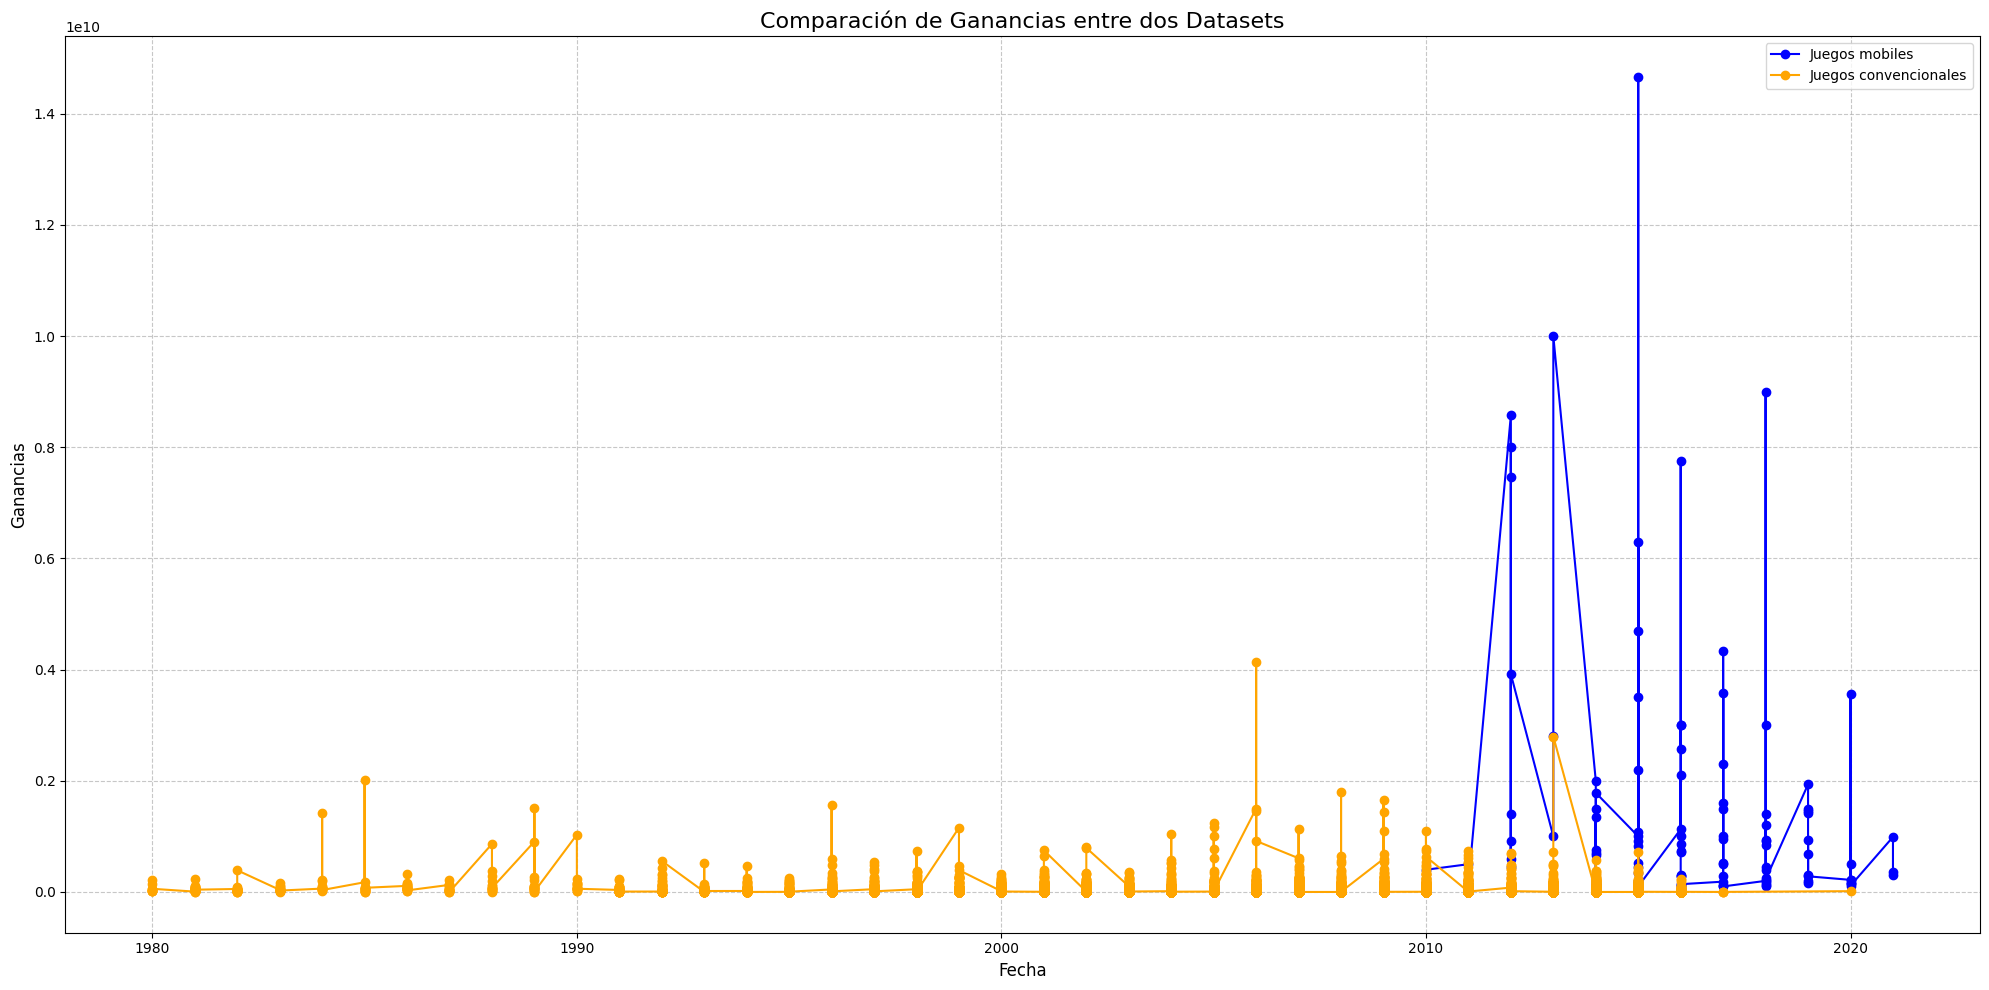

In [86]:
plt.figure(figsize=(20, 10))

plt.plot(mobile_games_fecha['Fecha'], mobile_games_fecha['Ganancias'], label='Juegos mobiles', color='blue', marker='o')

plt.plot(convencional_games_fecha['Fecha'], convencional_games_fecha['Ganancias'], label='Juegos convencionales', color='orange', marker='o')

plt.title('Comparación de Ganancias entre dos Datasets', fontsize=16)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Ganancias', fontsize=12)

plt.legend()
plt.grid(visible=True, which='major', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

### Sumatorio de las ganancias y agrupados por genero y año para compararlos entre si

##### Por año

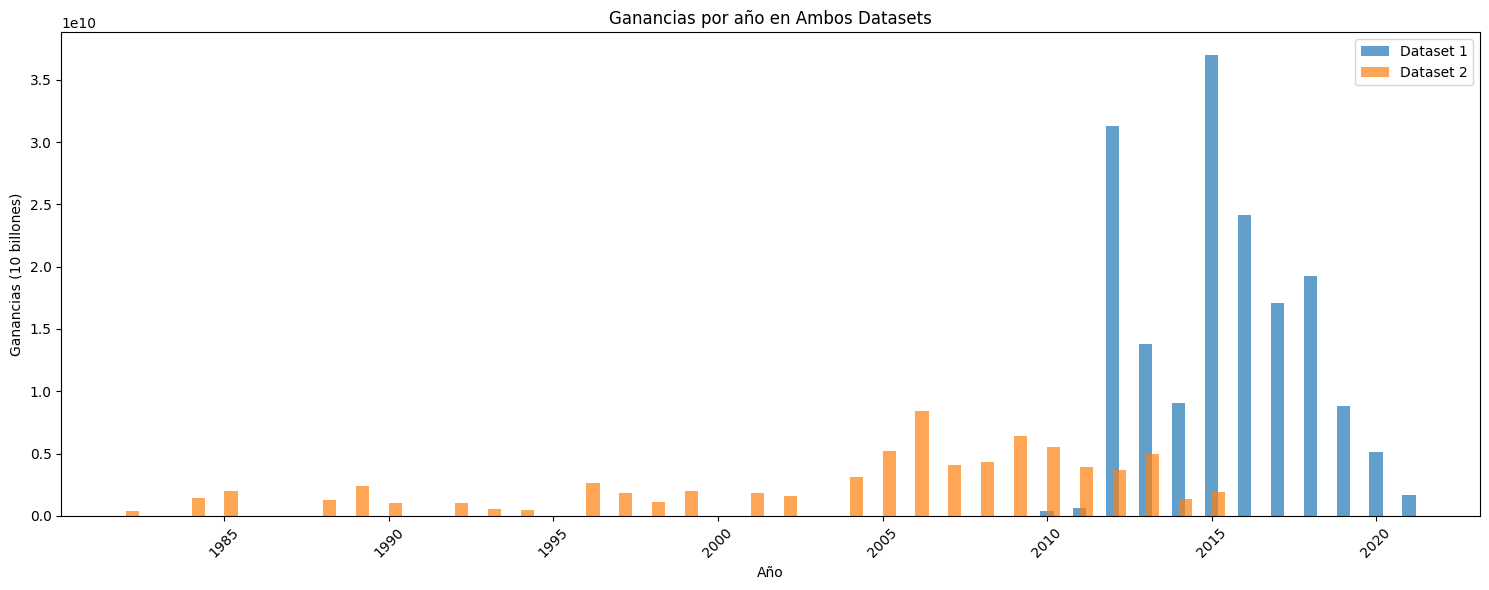

In [51]:
fecha_col = "Fecha"  
ganancias_col = "Ganancias"

dato1 = mobile_games_fecha.groupby(fecha_col)[ganancias_col].sum()
dato2 = convencional_games_100_fecha.groupby(fecha_col)[ganancias_col].sum()

plt.figure(figsize=(15, 6))

plt.bar(dato1.index, dato1.values, width=0.4, label="Dataset 1", align='center', alpha=0.7)

plt.bar(dato2.index, dato2.values, width=0.4, label="Dataset 2", align='edge', alpha=0.7)

plt.xlabel("Año")
plt.ylabel("Ganancias (10 billones)")
plt.title("Ganancias por año en Ambos Datasets")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

# Mostrar el gráfico
plt.show()

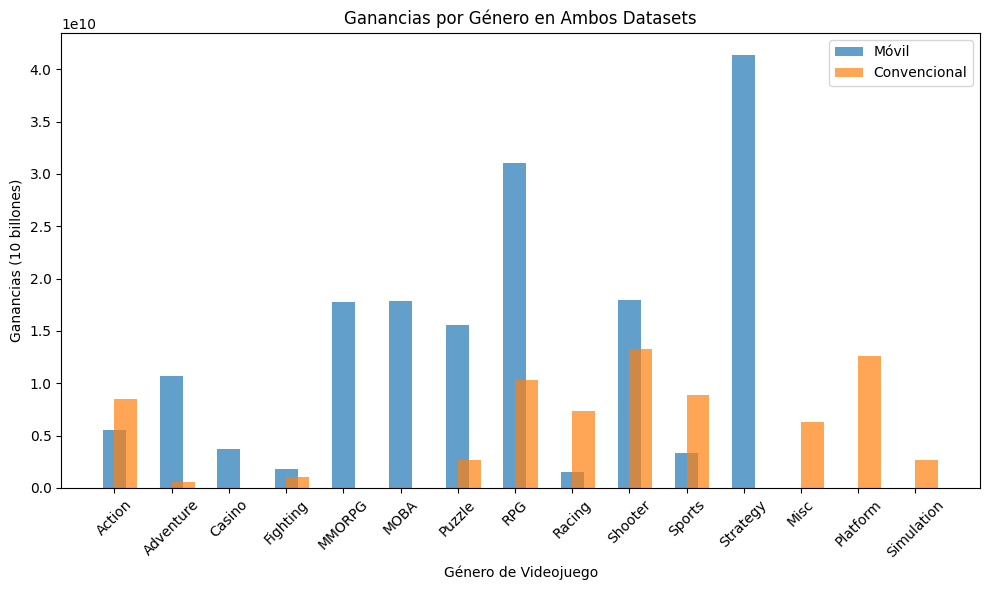

In [52]:
genero_col = "Genero"  
ganancias_col = "Ganancias"

data1 = mobile_games_fecha.groupby(genero_col)[ganancias_col].sum()
data2 = convencional_games_100_fecha.groupby(genero_col)[ganancias_col].sum()

plt.figure(figsize=(10, 6))

plt.bar(data1.index, data1.values, width=0.4, label="Móvil", align='center', alpha=0.7)

plt.bar(data2.index, data2.values, width=0.4, label="Convencional", align='edge', alpha=0.7)

plt.xlabel("Género de Videojuego")
plt.ylabel("Ganancias (10 billones)")
plt.title("Ganancias por Género en Ambos Datasets")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

# Mostrar el gráfico
plt.show()